# Trabajo Practico 3 - Neural Networks

**Alumno:** Tomas Gonzalez  
**Materia:** I302 - Aprendizaje Automatico y Aprendizaje Profundo

Este notebook es la entrega principal del TP. La idea es que se pueda leer de punta a punta como una secuencia de trabajo: primero miro los datos, despues construyo un baseline propio en NumPy, luego pruebo mejoras de training para elegir `M1`, y finalmente paso a PyTorch para comparar `M2` y buscar un `M3` mas fuerte.

Para mantener el notebook liviano, el codigo reutilizable esta en `src/` y los resultados de entrenamientos largos quedan guardados en `artifacts/`. Asi se pueden ver los analisis y los graficos sin volver a entrenar modelos que tardan bastante.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

RAIZ = Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

from src.data import (
    distribucion_clases,
    cargar_arrays_emnist,
    tabla_tamanos_split,
    indices_split_estratificado,
    resumir_dataset,
)
from src.experiments import (
    grilla_experimentos_por_defecto,
    cargar_historial,
    cargar_metrics,
    correr_grilla_experimentos,
    seleccionar_mejor_experimento,
)
from src.models import ClasificadorMLP
from src.plots import (
    graficar_distribucion_clases,
    graficar_confusion_diagnostics,
    graficar_confusion_matrix,
    graficar_loss_y_accuracy,
    graficar_grilla_metrics,
    graficar_dashboard_model_selection,
    graficar_samples,
    graficar_history_training,
)
from src.training import (
    evaluar_clasificador,
    schedule_decay_lineal,
    schedule_decay_exponencial,
    entrenar_full_batch_gradient_descent,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:.4f}".format

def mostrar_titulo(etiqueta: str, texto: str) -> None:
    display(
        Markdown(
            f"<h3 style='font-size:23px; margin:18px 0 8px 0;'>"
            f"{etiqueta} - {texto}</h3>"
        )
    )


DIR_ARTIFACTS = RAIZ / "artifacts"
NOMBRE_GRILLA = "grid_v2"
RUTA_RESUMEN_GRILLA = DIR_ARTIFACTS / f"{NOMBRE_GRILLA}_experiment_summary.csv"
N_CLASES = 47
TAMANO_CHUNK_EVAL = 32_768


## Punto 1 - Analisis y preprocesamiento de datos

El dataset es **EMNIST ByMerge**: imagenes manuscritas de `28 x 28` pixels con `47` clases. En este primer punto hago tres cosas basicas, pero importantes:

1. revisar tamano, rango de valores y distribucion de clases;
2. visualizar algunos samples para entender el tipo de imagen;
3. armar un split estratificado en `train`, `validation` y `test`, y verificar la normalizacion a `[0, 1]`.

Me interesa mirar la distribucion desde el comienzo porque, si las clases estan desbalanceadas, `accuracy` sola puede contar una historia incompleta. Por eso mas adelante uso tambien `F1 macro`.


In [2]:
X_imagenes, y_imagenes = cargar_arrays_emnist("Datasets", mmap_mode="r")
resumen = resumir_dataset(X_imagenes, y_imagenes)
print(
    f"Dataset cargado: {X_imagenes.shape[0]:,} samples, "
    f"shape={X_imagenes.shape[1:]}, classes={np.unique(y_imagenes).size}"
)


Dataset cargado: 809,555 samples, shape=(28, 28), classes=47


In [3]:
distribucion = distribucion_clases(y_imagenes)
class_count_summary = {
    "clase_mas_frecuente": int(distribucion.loc[distribucion["cantidad"].idxmax(), "clase"]),
    "n_mas_frecuente": int(distribucion["cantidad"].max()),
    "clase_menos_frecuente": int(distribucion.loc[distribucion["cantidad"].idxmin(), "clase"]),
    "n_menos_frecuente": int(distribucion["cantidad"].min()),
}
print(
    "Resumen de balance: "
    f"clase {class_count_summary['clase_mas_frecuente']} con {class_count_summary['n_mas_frecuente']:,} casos; "
    f"clase {class_count_summary['clase_menos_frecuente']} con {class_count_summary['n_menos_frecuente']:,} casos."
)


Resumen de balance: clase 1 con 44,604 casos; clase 40 con 2,861 casos.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 1 - Class Distribution de EMNIST ByMerge</h3>

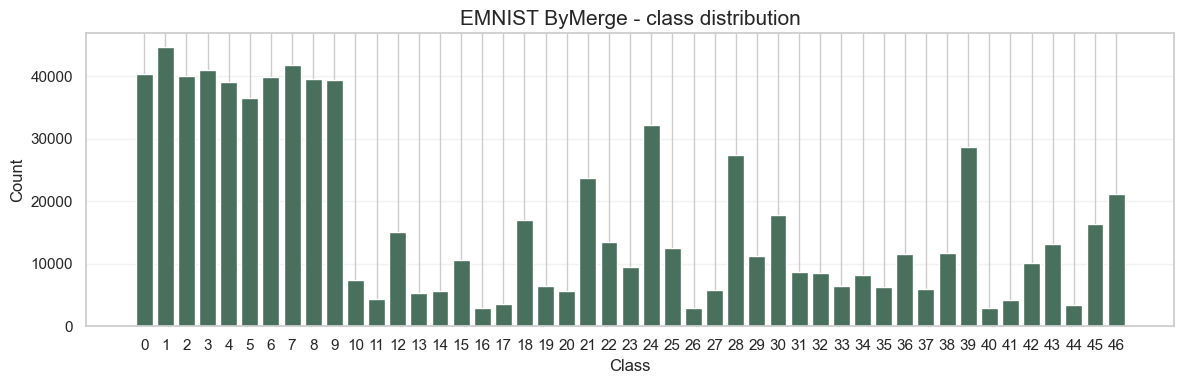

In [4]:
mostrar_titulo("Grafico 1", "Class Distribution de EMNIST ByMerge")
fig, _ = graficar_distribucion_clases(distribucion, title="EMNIST ByMerge - class distribution")
plt.show()


**Lectura.** La distribucion de clases esta bastante desbalanceada. La clase mas frecuente tiene `44.604` observaciones y la menos frecuente `2.861`, una diferencia de alrededor de `15.6x`. Por eso, durante el TP no miro solamente `accuracy`: tambien reporto `F1 macro`, que pesa a cada clase de forma mas pareja y deja ver si el modelo abandona clases chicas.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 2 - Tres Samples de Caracteres Manuscritos</h3>

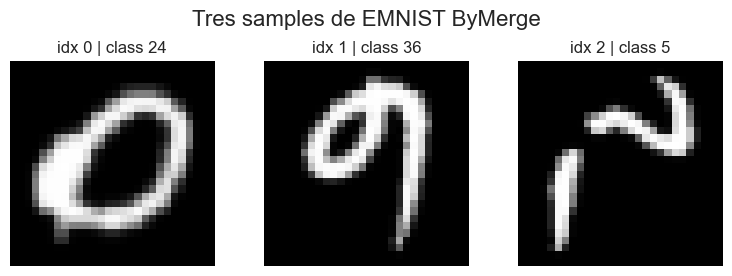

In [5]:
mostrar_titulo("Grafico 2", "Tres Samples de Caracteres Manuscritos")
fig, _ = graficar_samples(
    X_imagenes,
    y_imagenes,
    indices=[0, 1, 2],
    title="Tres samples de EMNIST ByMerge",
)
plt.show()


**Lectura.** Los samples muestran caracteres manuscritos con desplazamientos, grosores distintos y formas que a veces se parecen entre si. Esto anticipa el problema: no alcanza con reglas simples por pixel. El modelo tiene que aprender patrones relativamente robustos a la forma de escribir.


In [6]:
particiones = indices_split_estratificado(
    y_imagenes,
    train_size=0.70,
    validation_size=0.15,
    test_size=0.15,
    random_state=42,
)

split_sizes = tabla_tamanos_split(particiones)
print(
    f"Split estratificado: train={len(particiones.train):,}, "
    f"validation={len(particiones.validation):,}, test={len(particiones.test):,}."
)


Split estratificado: train=566,667, validation=121,410, test=121,478.


In [7]:
comparison = distribucion[["clase", "proporcion"]].rename(columns={"proporcion": "total"})

for split_name, indices in {
    "train": particiones.train,
    "validation": particiones.validation,
    "test": particiones.test,
}.items():
    split_dist = distribucion_clases(y_imagenes[indices])[["clase", "proporcion"]]
    split_dist = split_dist.rename(columns={"proporcion": split_name})
    comparison = comparison.merge(split_dist, on="clase", how="left")

split_columns = ["train", "validation", "test"]
comparison["max_abs_diff_vs_total"] = (
    comparison[split_columns].sub(comparison["total"], axis=0).abs().max(axis=1)
)

print(f"Maxima diferencia absoluta de proporciones por clase: {comparison['max_abs_diff_vs_total'].max():.6f}")


Maxima diferencia absoluta de proporciones por clase: 0.000014


In [8]:
def normalized_split_summary(
    split_name: str,
    indices: np.ndarray,
    *,
    tamano_chunk: int = TAMANO_CHUNK_EVAL,
) -> dict[str, object]:
    min_pixel = np.inf
    max_pixel = -np.inf

    for start in range(0, len(indices), tamano_chunk):
        indices_chunk = indices[start : start + tamano_chunk]
        X_chunk = np.asarray(X_imagenes[indices_chunk], dtype=np.float32) / 255.0
        min_pixel = min(min_pixel, float(X_chunk.min()))
        max_pixel = max(max_pixel, float(X_chunk.max()))

    return {
        "split": split_name,
        "shape_X": (len(indices), *X_imagenes.shape[1:]),
        "shape_y": (len(indices),),
        "dtype_X_normalizado": "float32",
        "min_pixel_normalizado": min_pixel,
        "max_pixel_normalizado": max_pixel,
    }


normalization_check = pd.DataFrame(
    [
        normalized_split_summary("train", particiones.train),
        normalized_split_summary("validation", particiones.validation),
        normalized_split_summary("test", particiones.test),
    ]
)

display(normalization_check)
print("Normalizacion verificada: pixeles en [0, 1] para train, validation y test.")


,split,shape_X,shape_y,dtype_X_normalizado,min_pixel_normalizado,max_pixel_normalizado
0,train,"(566667, 28, 28)","(566667,)",float32,0.0000,1.0000
1,validation,"(121410, 28, 28)","(121410,)",float32,0.0000,1.0000
2,test,"(121478, 28, 28)","(121478,)",float32,0.0000,1.0000


Normalizacion verificada: pixeles en [0, 1] para train, validation y test.


**Cierre del punto 1.** El split queda estratificado en `train`, `validation` y `test`, manteniendo casi iguales las proporciones de clases. Tambien queda verificado que la normalizacion lleva los pixels a `[0, 1]`. Como la base es grande, en el resto del TP evito materializar copias enormes cuando no hace falta y trabajo por chunks.


## Punto 2 - MLP basico implementado en NumPy

En este punto implemento un **MLP** desde cero usando NumPy. El objetivo de `M0` no es ser el mejor modelo, sino tener un baseline claro y propio contra el cual comparar las mejoras posteriores.

La arquitectura elegida por consigna es:

`784 -> 128 -> 64 -> 47`

Uso `ReLU` en las hidden layers y `softmax` en la output layer. Para una hidden layer:

$$
a^{(l)} = Z^{(l-1)}W^{(l)} + b^{(l)}
$$

$$
Z^{(l)} = \mathrm{ReLU}(a^{(l)}) = \max(0, a^{(l)})
$$

En la output layer:

$$
\hat{y}_{k} = \frac{e^{a^{(L)}_k}}{\sum_j e^{a^{(L)}_j}}
$$

La funcion de costo es `cross-entropy` multiclass:

$$
J(W,b) = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K}\mathbb{1}(y_i=k)\log(\hat{y}_{ik})
$$

Con `softmax + cross-entropy`, el gradiente de salida se simplifica a:

$$
\frac{\partial J}{\partial a^{(L)}} = \frac{\hat{Y} - Y}{N}
$$

Entreno `M0` con `full-batch gradient descent` durante `100` epochs. Internamente uso chunks grandes para no quedarme sin memoria, pero el update de pesos sigue siendo full-batch: se acumula el gradiente de todo `train` y recien despues se actualiza.


In [9]:
M0_ARCHITECTURE = [28 * 28, 128, 64, 47]

m0_preview = ClasificadorMLP(M0_ARCHITECTURE, random_state=42, dtype=np.float32)
parameter_summary = pd.DataFrame(
    [
        {
            "parametro": name,
            "shape": value.shape,
            "cantidad": value.size,
            "dtype": value.dtype,
        }
        for name, value in m0_preview.parametros.items()
    ]
)

print(f"M0 queda definido con {parameter_summary['cantidad'].sum():,} parametros entrenables.")


M0 queda definido con 111,791 parametros entrenables.


In [10]:
FORCE_RETRAIN_M0 = False
M0_HISTORY_PATH = DIR_ARTIFACTS / "m0_history.npz"
M0_METRICS_PATH = DIR_ARTIFACTS / "m0_metrics.npz"

if FORCE_RETRAIN_M0 or not (M0_HISTORY_PATH.exists() and M0_METRICS_PATH.exists()):
    m0 = ClasificadorMLP(M0_ARCHITECTURE, random_state=42, dtype=np.float32)
    history_m0 = entrenar_full_batch_gradient_descent(
        m0,
        X_imagenes,
        y_imagenes,
        particiones.train,
        particiones.validation,
        epochs=100,
        learning_rate=0.1,
        tamano_chunk_gradiente=32_768,
        tamano_chunk_eval=TAMANO_CHUNK_EVAL,
        n_classes=N_CLASES,
        verbose=True,
    )
    m0_train_metrics = evaluar_clasificador(m0, X_imagenes, y_imagenes, particiones.train, tamano_chunk=TAMANO_CHUNK_EVAL, n_classes=N_CLASES)
    m0_validation_metrics = evaluar_clasificador(m0, X_imagenes, y_imagenes, particiones.validation, tamano_chunk=TAMANO_CHUNK_EVAL, n_classes=N_CLASES)
else:
    history_m0 = cargar_historial(M0_HISTORY_PATH)
    m0_metrics = cargar_metrics(M0_METRICS_PATH)
    m0_train_metrics = {
        "loss": float(m0_metrics["train_loss"]),
        "accuracy": float(m0_metrics["train_accuracy"]),
        "f1_macro": float(m0_metrics["train_f1_macro"]),
        "confusion_matrix": m0_metrics["train_confusion_matrix"],
        "n_samples": int(m0_metrics["train_n_samples"]),
    }
    m0_validation_metrics = {
        "loss": float(m0_metrics["validation_loss"]),
        "accuracy": float(m0_metrics["validation_accuracy"]),
        "f1_macro": float(m0_metrics["validation_f1_macro"]),
        "confusion_matrix": m0_metrics["validation_confusion_matrix"],
        "n_samples": int(m0_metrics["validation_n_samples"]),
    }

history_m0_df = pd.DataFrame(history_m0)
print(f"M0 listo: {len(history_m0_df)} epochs disponibles en artifacts.")


M0 listo: 100 epochs disponibles en artifacts.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 3 - M0: Cross-Entropy y Accuracy por Epoch</h3>

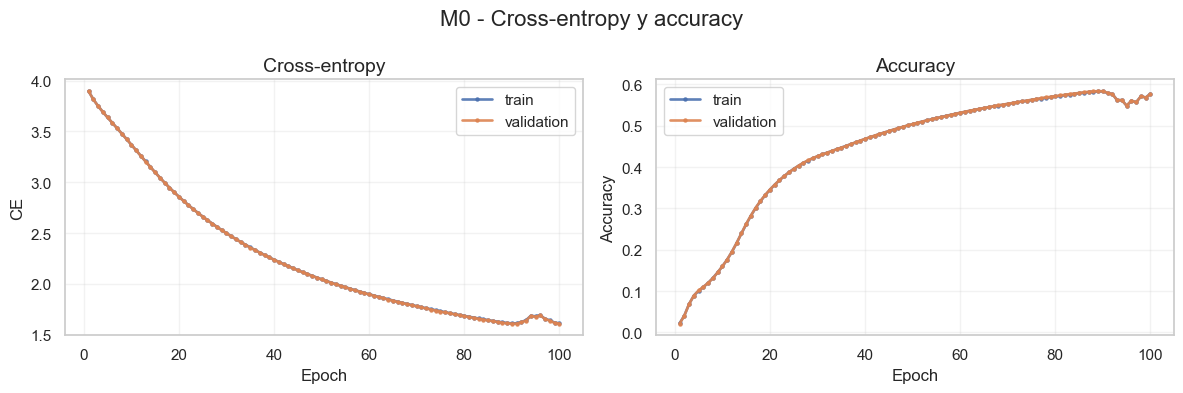

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 4 - M0: F1 Macro por Epoch</h3>

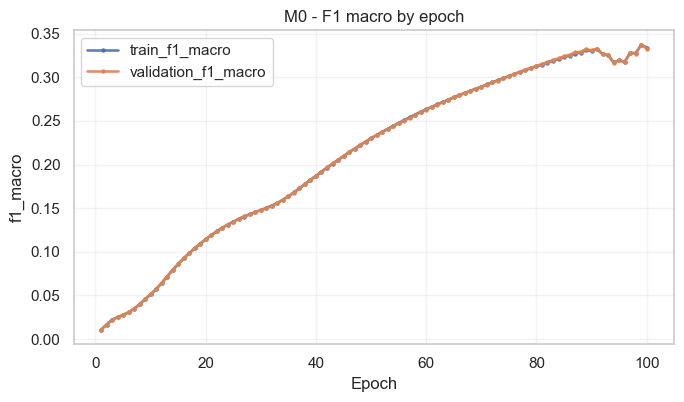

In [11]:
mostrar_titulo("Grafico 3", "M0: Cross-Entropy y Accuracy por Epoch")
fig, _ = graficar_loss_y_accuracy(history_m0, title="M0 - Cross-entropy y accuracy")
plt.show()

mostrar_titulo("Grafico 4", "M0: F1 Macro por Epoch")
fig, _ = graficar_history_training(history_m0, metric="f1_macro")
plt.title("M0 - F1 macro by epoch")
plt.show()


**Lectura.** `M0` aprende, pero queda corto. La `cross-entropy` de `validation` baja hasta aproximadamente `1.609` y la `accuracy` termina cerca de `0.577`. El `F1 macro` queda alrededor de `0.333`, bastante bajo para un problema con 47 clases. La diferencia entre `train` y `validation` no es grande, asi que el problema principal no parece ser overfitting, sino underfitting: el baseline todavia no tiene suficiente capacidad/training para capturar bien los patrones.


In [12]:
m0_metrics_table = pd.DataFrame(
    [
        {
            "modelo": "M0",
            "split": "train",
            "n": m0_train_metrics["n_samples"],
            "accuracy": m0_train_metrics["accuracy"],
            "cross_entropy": m0_train_metrics["loss"],
            "f1_macro": m0_train_metrics["f1_macro"],
        },
        {
            "modelo": "M0",
            "split": "validation",
            "n": m0_validation_metrics["n_samples"],
            "accuracy": m0_validation_metrics["accuracy"],
            "cross_entropy": m0_validation_metrics["loss"],
            "f1_macro": m0_validation_metrics["f1_macro"],
        },
    ]
)

mostrar_titulo("Tabla 1", "Metrics de M0 en Train y Validation")
m0_metrics_table


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Tabla 1 - Metrics de M0 en Train y Validation</h3>

,modelo,split,n,accuracy,cross_entropy,f1_macro
0,M0,train,566667,0.5776,1.6118,0.3340
1,M0,validation,121410,0.5769,1.6092,0.3326


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 5 - M0: Confusion Diagnostics en Validation</h3>

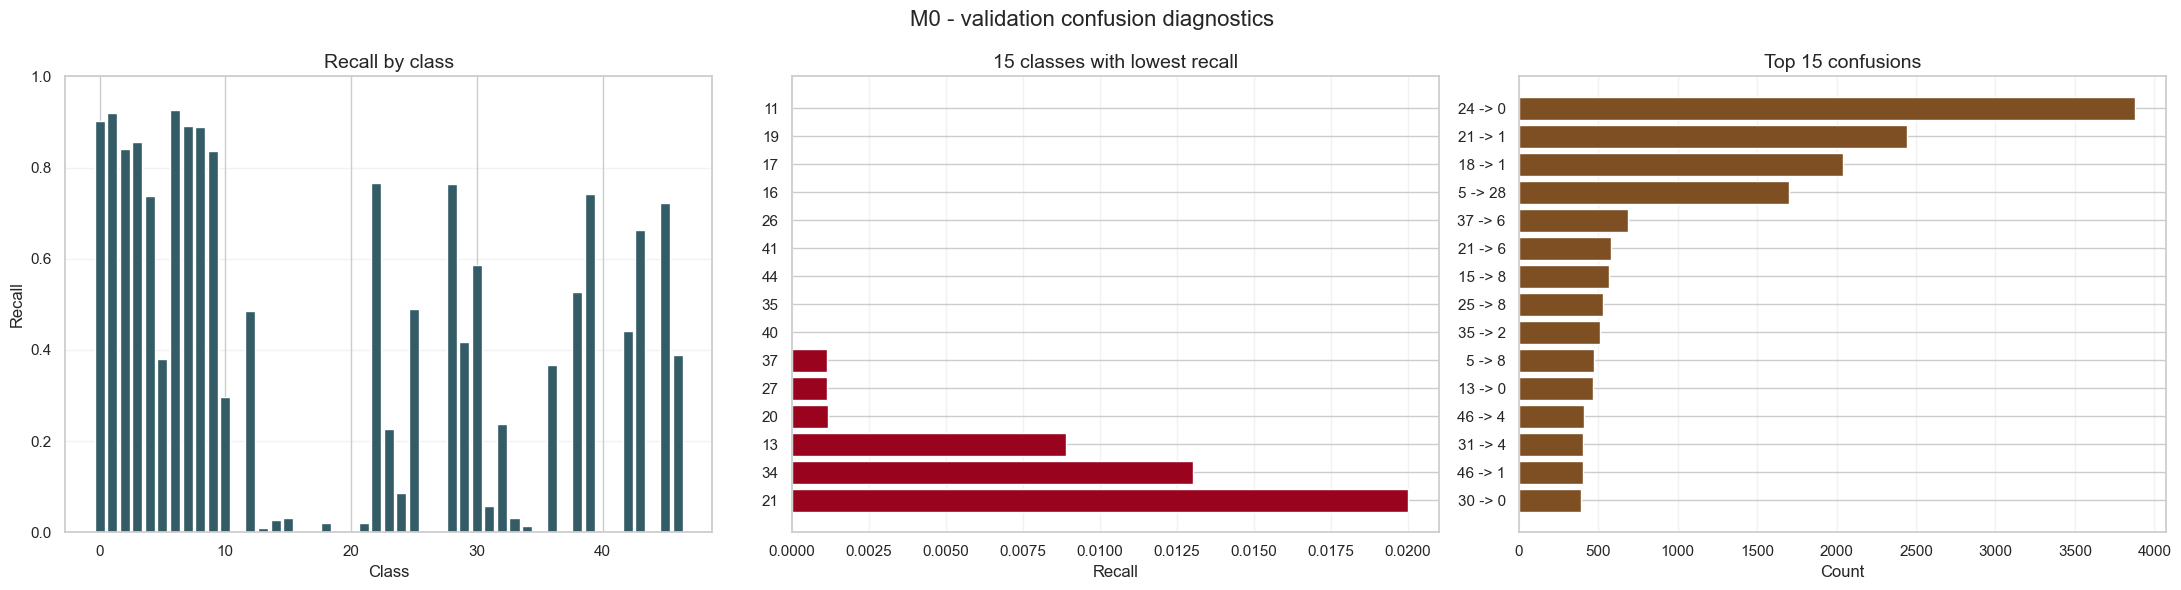

In [13]:
mostrar_titulo("Grafico 5", "M0: Confusion Diagnostics en Validation")
fig, axes, m0_per_class, m0_top_confusions = graficar_confusion_diagnostics(
    m0_validation_metrics["confusion_matrix"],
    top_n=15,
    title="M0 - validation confusion diagnostics",
)
plt.show()


**Lectura.** El `confusion diagnostics` explica por que el `F1 macro` es bajo. Varias clases tienen recall casi nulo, y aparecen confusiones fuertes como `24 -> 0`, `21 -> 1` y `18 -> 1`. En otras palabras, `M0` tiende a mandar muchos casos hacia pocas clases dominantes. Esto es justo lo que queria medir con `F1 macro` y `confusion matrix`, no solo con `accuracy`.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 6 - M0: Normalized Confusion Matrix en Validation</h3>

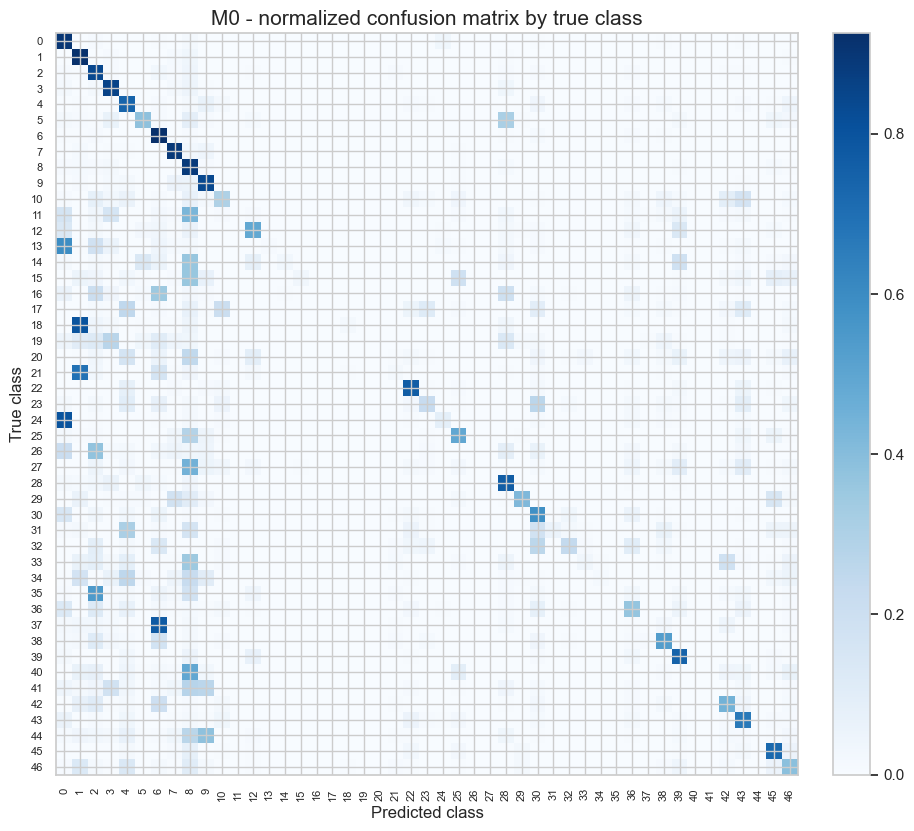

In [14]:
mostrar_titulo("Grafico 6", "M0: Normalized Confusion Matrix en Validation")
fig, _ = graficar_confusion_matrix(
    m0_validation_metrics["confusion_matrix"],
    title="M0 - normalized confusion matrix by true class",
    normalizar=True,
    annotate=False,
)
fig.set_size_inches(10, 9)
plt.show()


**Lectura.** La `confusion matrix` normalizada de `M0` tiene una diagonal debil y bastante masa fuera de la diagonal. Visualmente se ve que los errores no son casos aislados: hay grupos de clases que se confunden de forma sistematica. Esto confirma que `M0` sirve como punto de partida, pero no como modelo final.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 7 - M0: Normalized Confusion Matrix en Train</h3>

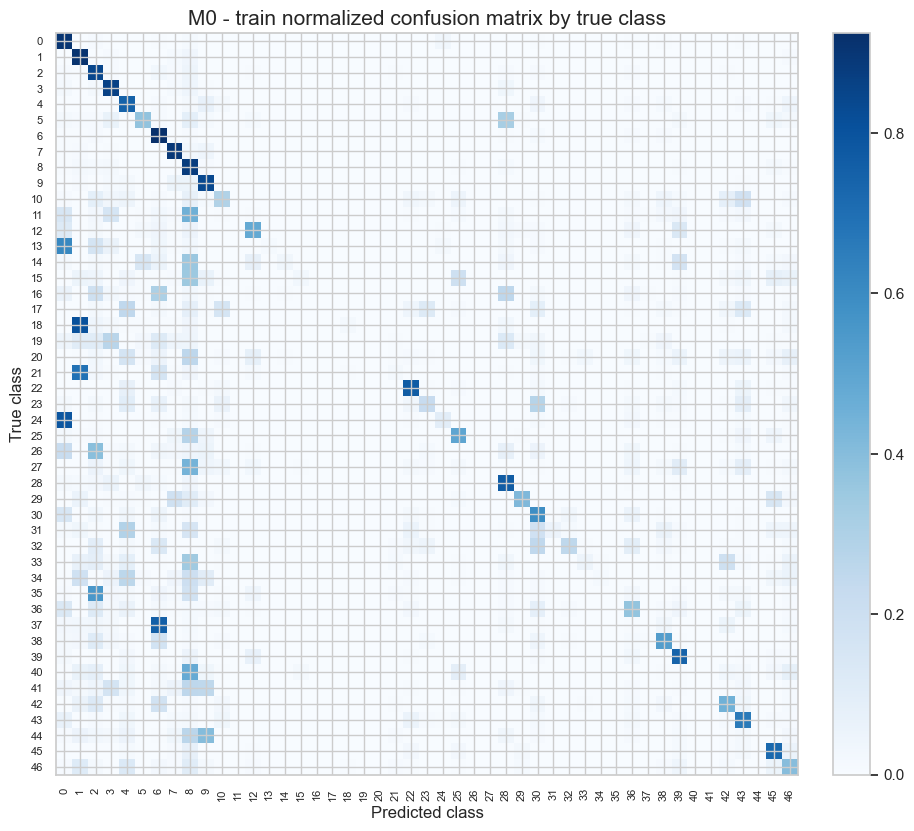

In [15]:
mostrar_titulo("Grafico 7", "M0: Normalized Confusion Matrix en Train")
fig, _ = graficar_confusion_matrix(
    m0_train_metrics["confusion_matrix"],
    title="M0 - train normalized confusion matrix by true class",
    normalizar=True,
    annotate=False,
)
fig.set_size_inches(10, 9)
plt.show()


**Lectura.** La `confusion matrix` de `train` se parece mucho a la de `validation`. Eso refuerza la idea anterior: no estoy viendo un modelo que memoriza `train` y falla en `validation`, sino un modelo que todavia no aprende representaciones suficientemente buenas ni siquiera sobre `train`.


## Punto 3 - Mejoras de training y seleccion de M1

Para elegir `M1` armo una grilla de modelos `MA` a `MP`. La intencion es probar las mejoras pedidas por la consigna de forma ordenada, no ir cambiando cosas al azar.

Las familias de experimentos cubren:

- `mini-batch SGD`;
- `learning rate schedules` lineal y exponencial;
- `Adam`;
- regularizacion con `L2` y `early stopping`;
- cambios de arquitectura y cantidad de parametros.

El criterio principal para elegir es menor `validation cross-entropy`. Uso `F1 macro` como criterio secundario porque el dataset esta desbalanceado. Tambien miro tiempo y tamano del modelo para no elegir una red mas grande si la mejora no lo justifica.


In [16]:
experiment_configs = grilla_experimentos_por_defecto()

grid_design = pd.DataFrame(
    [
        {
            "modelo": cfg.model_id,
            "descripcion": cfg.description,
            "arquitectura": "-".join(map(str, cfg.architecture)),
            "optimizer": cfg.optimizer,
            "batch_size": cfg.batch_size,
            "epochs_planificadas": cfg.epochs,
            "learning_rate": cfg.learning_rate,
            "schedule": cfg.schedule,
            "final_lr": cfg.final_lr,
            "decay_rate": cfg.decay_rate,
            "min_lr": cfg.min_lr,
            "l2_lambda": cfg.l2_lambda,
            "early_stopping": cfg.early_stopping,
        }
        for cfg in experiment_configs
    ]
)

print(
    f"Grilla preparada con {len(grid_design)} modelos: SGD/Adam, schedules lineal/exponencial, "
    "distintas arquitecturas y regularizacion L2/early stopping."
)


Grilla preparada con 16 modelos: SGD/Adam, schedules lineal/exponencial, distintas arquitecturas y regularizacion L2/early stopping.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 8 - Learning Rate Schedules de la Grilla MA-MP</h3>

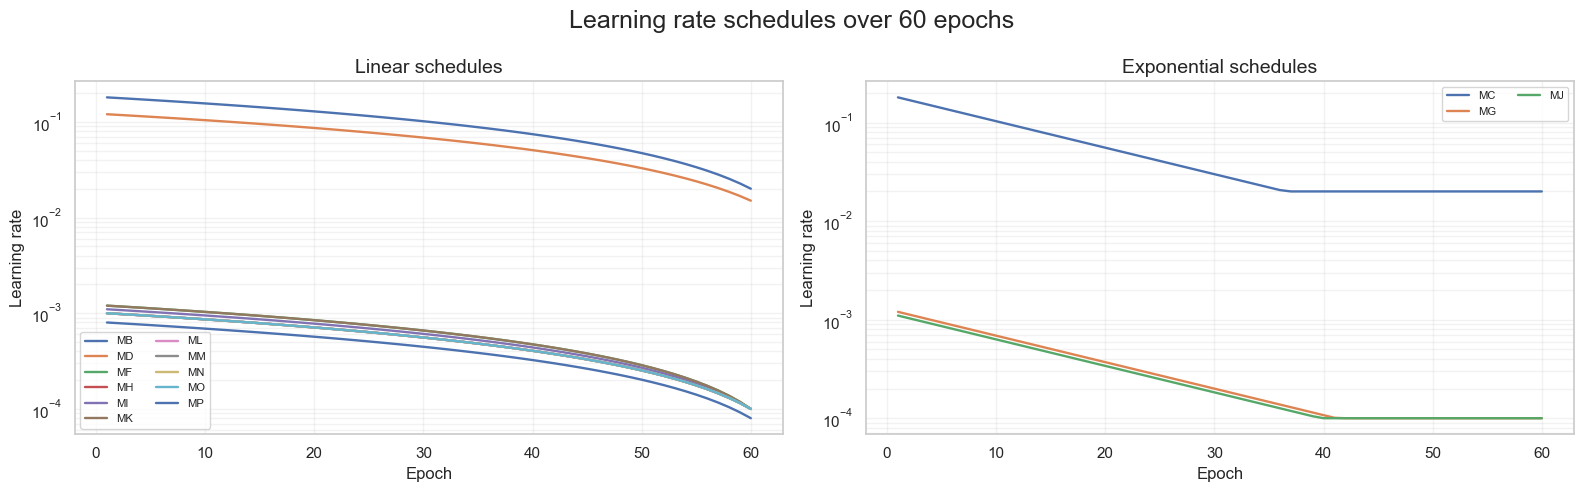

In [17]:
mostrar_titulo("Grafico 8", "Learning Rate Schedules de la Grilla MA-MP")
COMMON_SCHEDULE_EPOCHS = 60
schedule_epochs = np.arange(1, COMMON_SCHEDULE_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)

for cfg in experiment_configs:
    if cfg.schedule == "linear":
        lrs = [
            schedule_decay_lineal(
                epoch,
                initial_lr=cfg.learning_rate,
                final_lr=cfg.final_lr,
                total_epochs=COMMON_SCHEDULE_EPOCHS,
            )
            for epoch in schedule_epochs
        ]
        axes[0].plot(schedule_epochs, lrs, linewidth=1.7, label=cfg.model_id)
    elif cfg.schedule == "exponential":
        lrs = [
            schedule_decay_exponencial(
                epoch,
                initial_lr=cfg.learning_rate,
                decay_rate=cfg.decay_rate,
                min_lr=cfg.min_lr,
            )
            for epoch in schedule_epochs
        ]
        axes[1].plot(schedule_epochs, lrs, linewidth=1.7, label=cfg.model_id)

axes[0].set_title("Linear schedules", fontsize=14)
axes[1].set_title("Exponential schedules", fontsize=14)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Learning rate")
    ax.set_yscale("log")
    ax.grid(alpha=0.25, which="both")
    ax.legend(ncol=2, fontsize=8)

fig.suptitle("Learning rate schedules over 60 epochs", fontsize=18)
fig.tight_layout()
plt.show()


**Lectura.** Grafique los `learning rate schedules` en la misma escala de `60` epochs. En escala logaritmica se nota que `Adam` trabaja con `learning rates` mucho mas chicos que `SGD`. Separar schedules lineales y exponenciales ayuda a ver como baja el paso de actualizacion durante el training.


In [18]:
FORCE_RETRAIN_GRID = False

if FORCE_RETRAIN_GRID or not RUTA_RESUMEN_GRILLA.exists():
    grid_summary = correr_grilla_experimentos(
        experiment_configs,
        X_imagenes,
        y_imagenes,
        particiones.train,
        particiones.validation,
        dir_artifacts=DIR_ARTIFACTS,
        nombre_grilla=NOMBRE_GRILLA,
        force=FORCE_RETRAIN_GRID,
        tamano_curva_train=150_000,
        tamano_curva_validation=None,
        tamano_chunk_eval=TAMANO_CHUNK_EVAL,
        n_classes=N_CLASES,
        verbose=True,
    )
else:
    grid_summary = pd.read_csv(RUTA_RESUMEN_GRILLA)

best_row = seleccionar_mejor_experimento(grid_summary)
grid_summary_sorted = grid_summary.sort_values("validation_loss").reset_index(drop=True)

print(
    f"Mejor candidato de la grilla inicial: {best_row['model_id']} "
    f"con CE validation={best_row['validation_loss']:.4f}."
)


Mejor candidato de la grilla inicial: MO con CE validation=0.3060.


### 3.a - Ablation de mejoras

Para cumplir explicitamente con el inciso `3.a`, separo el efecto de cada mejora. No muestro toda la grilla en esta tabla, sino los modelos que sirven como controles:

- `M0`: baseline con `full-batch gradient descent`;
- `MA`: introduce `mini-batch SGD`;
- `MB` y `MC`: prueban `linear` y `exponential schedule` sobre SGD;
- `ME`: cambia el optimizer a `Adam`;
- `MH`: agrega `L2 + early stopping` sobre la arquitectura base;
- `MO`: muestra la combinacion que termina siendo mas competitiva.

Asi la comparacion queda mas facil de leer: que mejora se agrego, contra que control se compara, cuanto cambia la performance y cuanto tarda.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Tabla 2 - Ablation Summary del Punto 3.a</h3>

,mejora,modelo,control,CE val,accuracy val,F1 val,total min,sec/epoch,epochs
0,Baseline full-batch,M0,-,1.6092,0.5769,0.3326,9.5240,5.7144,100
1,Mini-batch SGD,MA,M0,0.3940,0.8673,0.8280,4.7291,4.7291,60
2,Schedule lineal,MB,MA,0.4126,0.8628,0.8175,4.7212,4.7212,60
3,Schedule exponencial,MC,MA,0.4748,0.8459,0.7900,4.7176,4.7176,60
4,Adam,ME,MA,0.3607,0.8771,0.8429,4.8237,4.8237,60
5,L2 + Early Stopping,MH,MF,0.3632,0.8754,0.8387,4.8310,4.8310,60
6,Combinacion final M1,MO,MM / MP,0.3060,0.8910,0.8627,8.9963,15.4222,35


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 9 - Ablation: Performance y Training Time</h3>

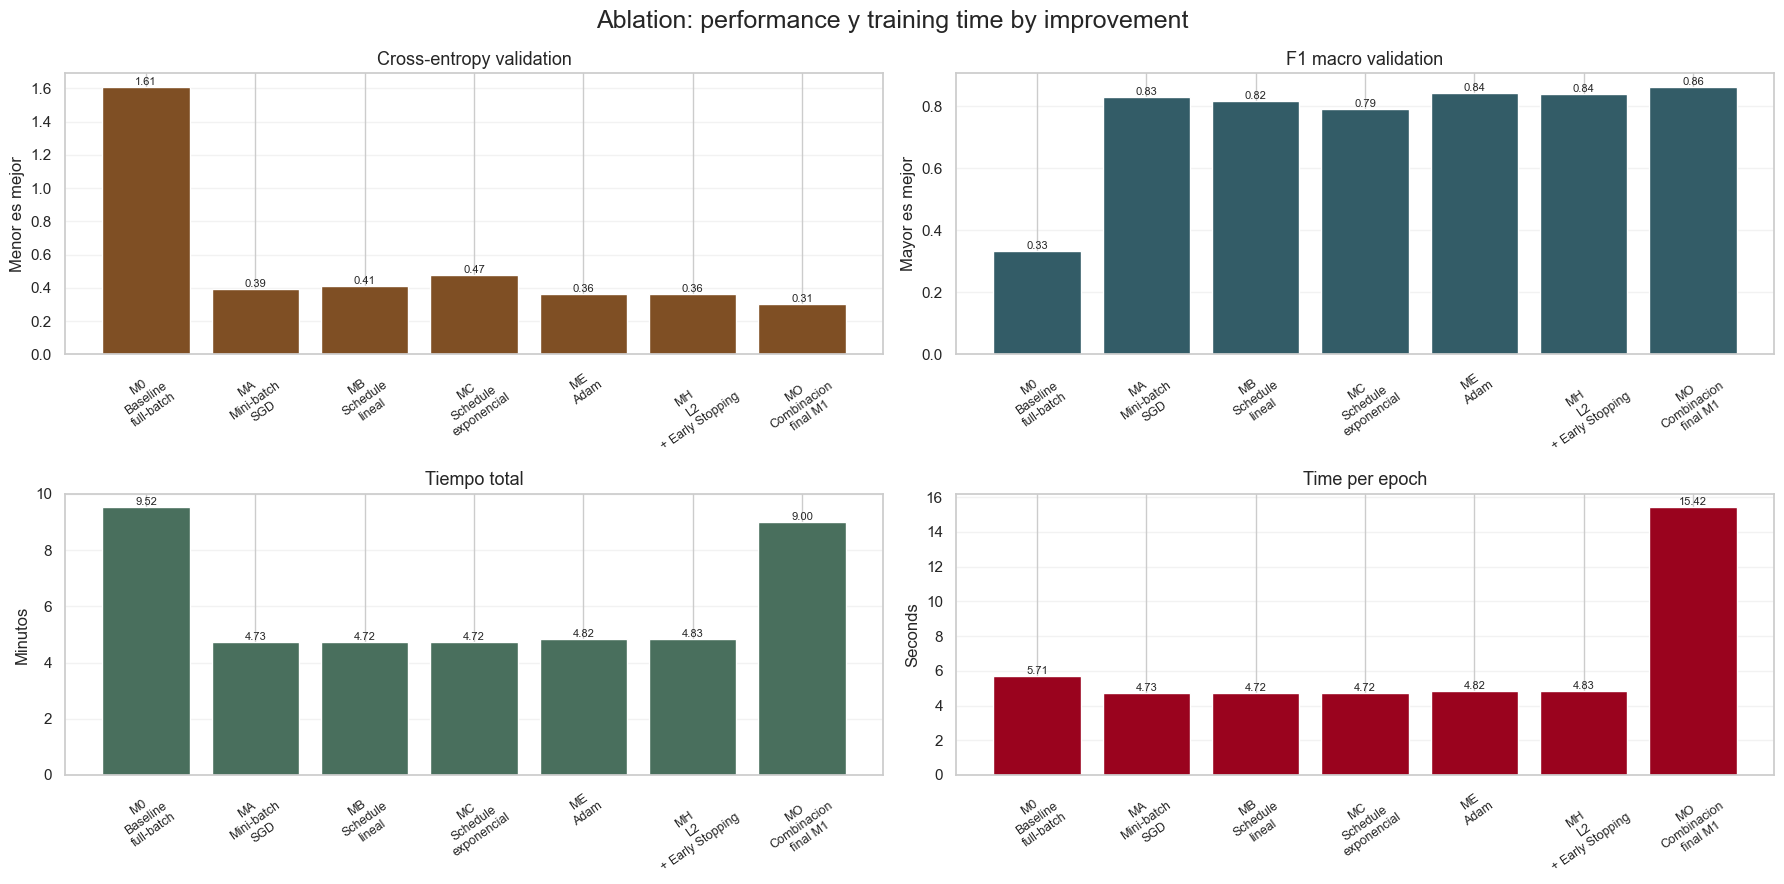

In [19]:
ablation_rows = []

ablation_rows.append(
    {
        "mejora": "Baseline full-batch",
        "modelo": "M0",
        "control": "-",
        "validation_loss": m0_validation_metrics["loss"],
        "validation_accuracy": m0_validation_metrics["accuracy"],
        "validation_f1_macro": m0_validation_metrics["f1_macro"],
        "total_seconds": float(history_m0_df["elapsed_seconds"].sum()),
        "seconds_per_epoch": float(history_m0_df["elapsed_seconds"].mean()),
        "completed_epochs": len(history_m0_df),
    }
)

for model_id, mejora, control in [
    ("MA", "Mini-batch SGD", "M0"),
    ("MB", "Schedule lineal", "MA"),
    ("MC", "Schedule exponencial", "MA"),
    ("ME", "Adam", "MA"),
    ("MH", "L2 + Early Stopping", "MF"),
    ("MO", "Combinacion final M1", "MM / MP"),
]:
    fila = grid_summary.loc[grid_summary["model_id"] == model_id].iloc[0]
    ablation_rows.append(
        {
            "mejora": mejora,
            "modelo": model_id,
            "control": control,
            "validation_loss": fila["validation_loss"],
            "validation_accuracy": fila["validation_accuracy"],
            "validation_f1_macro": fila["validation_f1_macro"],
            "total_seconds": fila["total_seconds"],
            "seconds_per_epoch": fila["mean_epoch_seconds"],
            "completed_epochs": fila["completed_epochs"],
        }
    )

ablation_summary = pd.DataFrame(ablation_rows)
ablation_summary["total_minutes"] = ablation_summary["total_seconds"] / 60

ablation_table = ablation_summary[
    [
        "mejora",
        "modelo",
        "control",
        "validation_loss",
        "validation_accuracy",
        "validation_f1_macro",
        "total_minutes",
        "seconds_per_epoch",
        "completed_epochs",
    ]
].copy()

ablation_table = ablation_table.rename(
    columns={
        "validation_loss": "CE val",
        "validation_accuracy": "accuracy val",
        "validation_f1_macro": "F1 val",
        "total_minutes": "total min",
        "seconds_per_epoch": "sec/epoch",
        "completed_epochs": "epochs",
    }
)

mostrar_titulo("Tabla 2", "Ablation Summary del Punto 3.a")
display(ablation_table)

mostrar_titulo("Grafico 9", "Ablation: Performance y Training Time")
plot_data = ablation_summary.copy()
plot_data["etiqueta"] = plot_data["modelo"] + "\n" + plot_data["mejora"].str.replace(" ", "\n", n=1)

fig, axes = plt.subplots(2, 2, figsize=(18, 9))
axes = axes.ravel()
especificaciones = [
    ("validation_loss", "Cross-entropy validation", "Menor es mejor", "#7f4f24"),
    ("validation_f1_macro", "F1 macro validation", "Mayor es mejor", "#335c67"),
    ("total_minutes", "Tiempo total", "Minutos", "#496f5d"),
    ("seconds_per_epoch", "Time per epoch", "Seconds", "#9a031e"),
]

for ax, (column, title, ylabel, color) in zip(axes, especificaciones):
    barras = ax.bar(plot_data["etiqueta"], plot_data[column], color=color)
    ax.set_title(title, fontsize=13)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=35, labelsize=9)
    ax.grid(axis="y", alpha=0.25)
    for bar in barras:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

fig.suptitle("Ablation: performance y training time by improvement", fontsize=18)
fig.tight_layout()
plt.show()


**Lectura.** La mejora mas grande aparece al pasar de `M0` a `MA`: `validation cross-entropy` baja de `1.6092` a `0.3940`, y `F1 macro` sube de `0.3326` a `0.8280`. Eso muestra que `mini-batch SGD` cambia mucho el comportamiento del training. Sobre SGD, los schedules probados no mejoran al control constante. En cambio, `Adam` si mejora con un costo por epoch parecido. La regularizacion aislada no gana por si sola en la arquitectura base, pero se vuelve importante cuando aumento la capacidad. La mejor combinacion de esta etapa es `MO`, que queda con `validation CE` cercana a `0.306`.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 10 - Grilla MA-MP: Cross-Entropy, Accuracy y F1 Macro</h3>

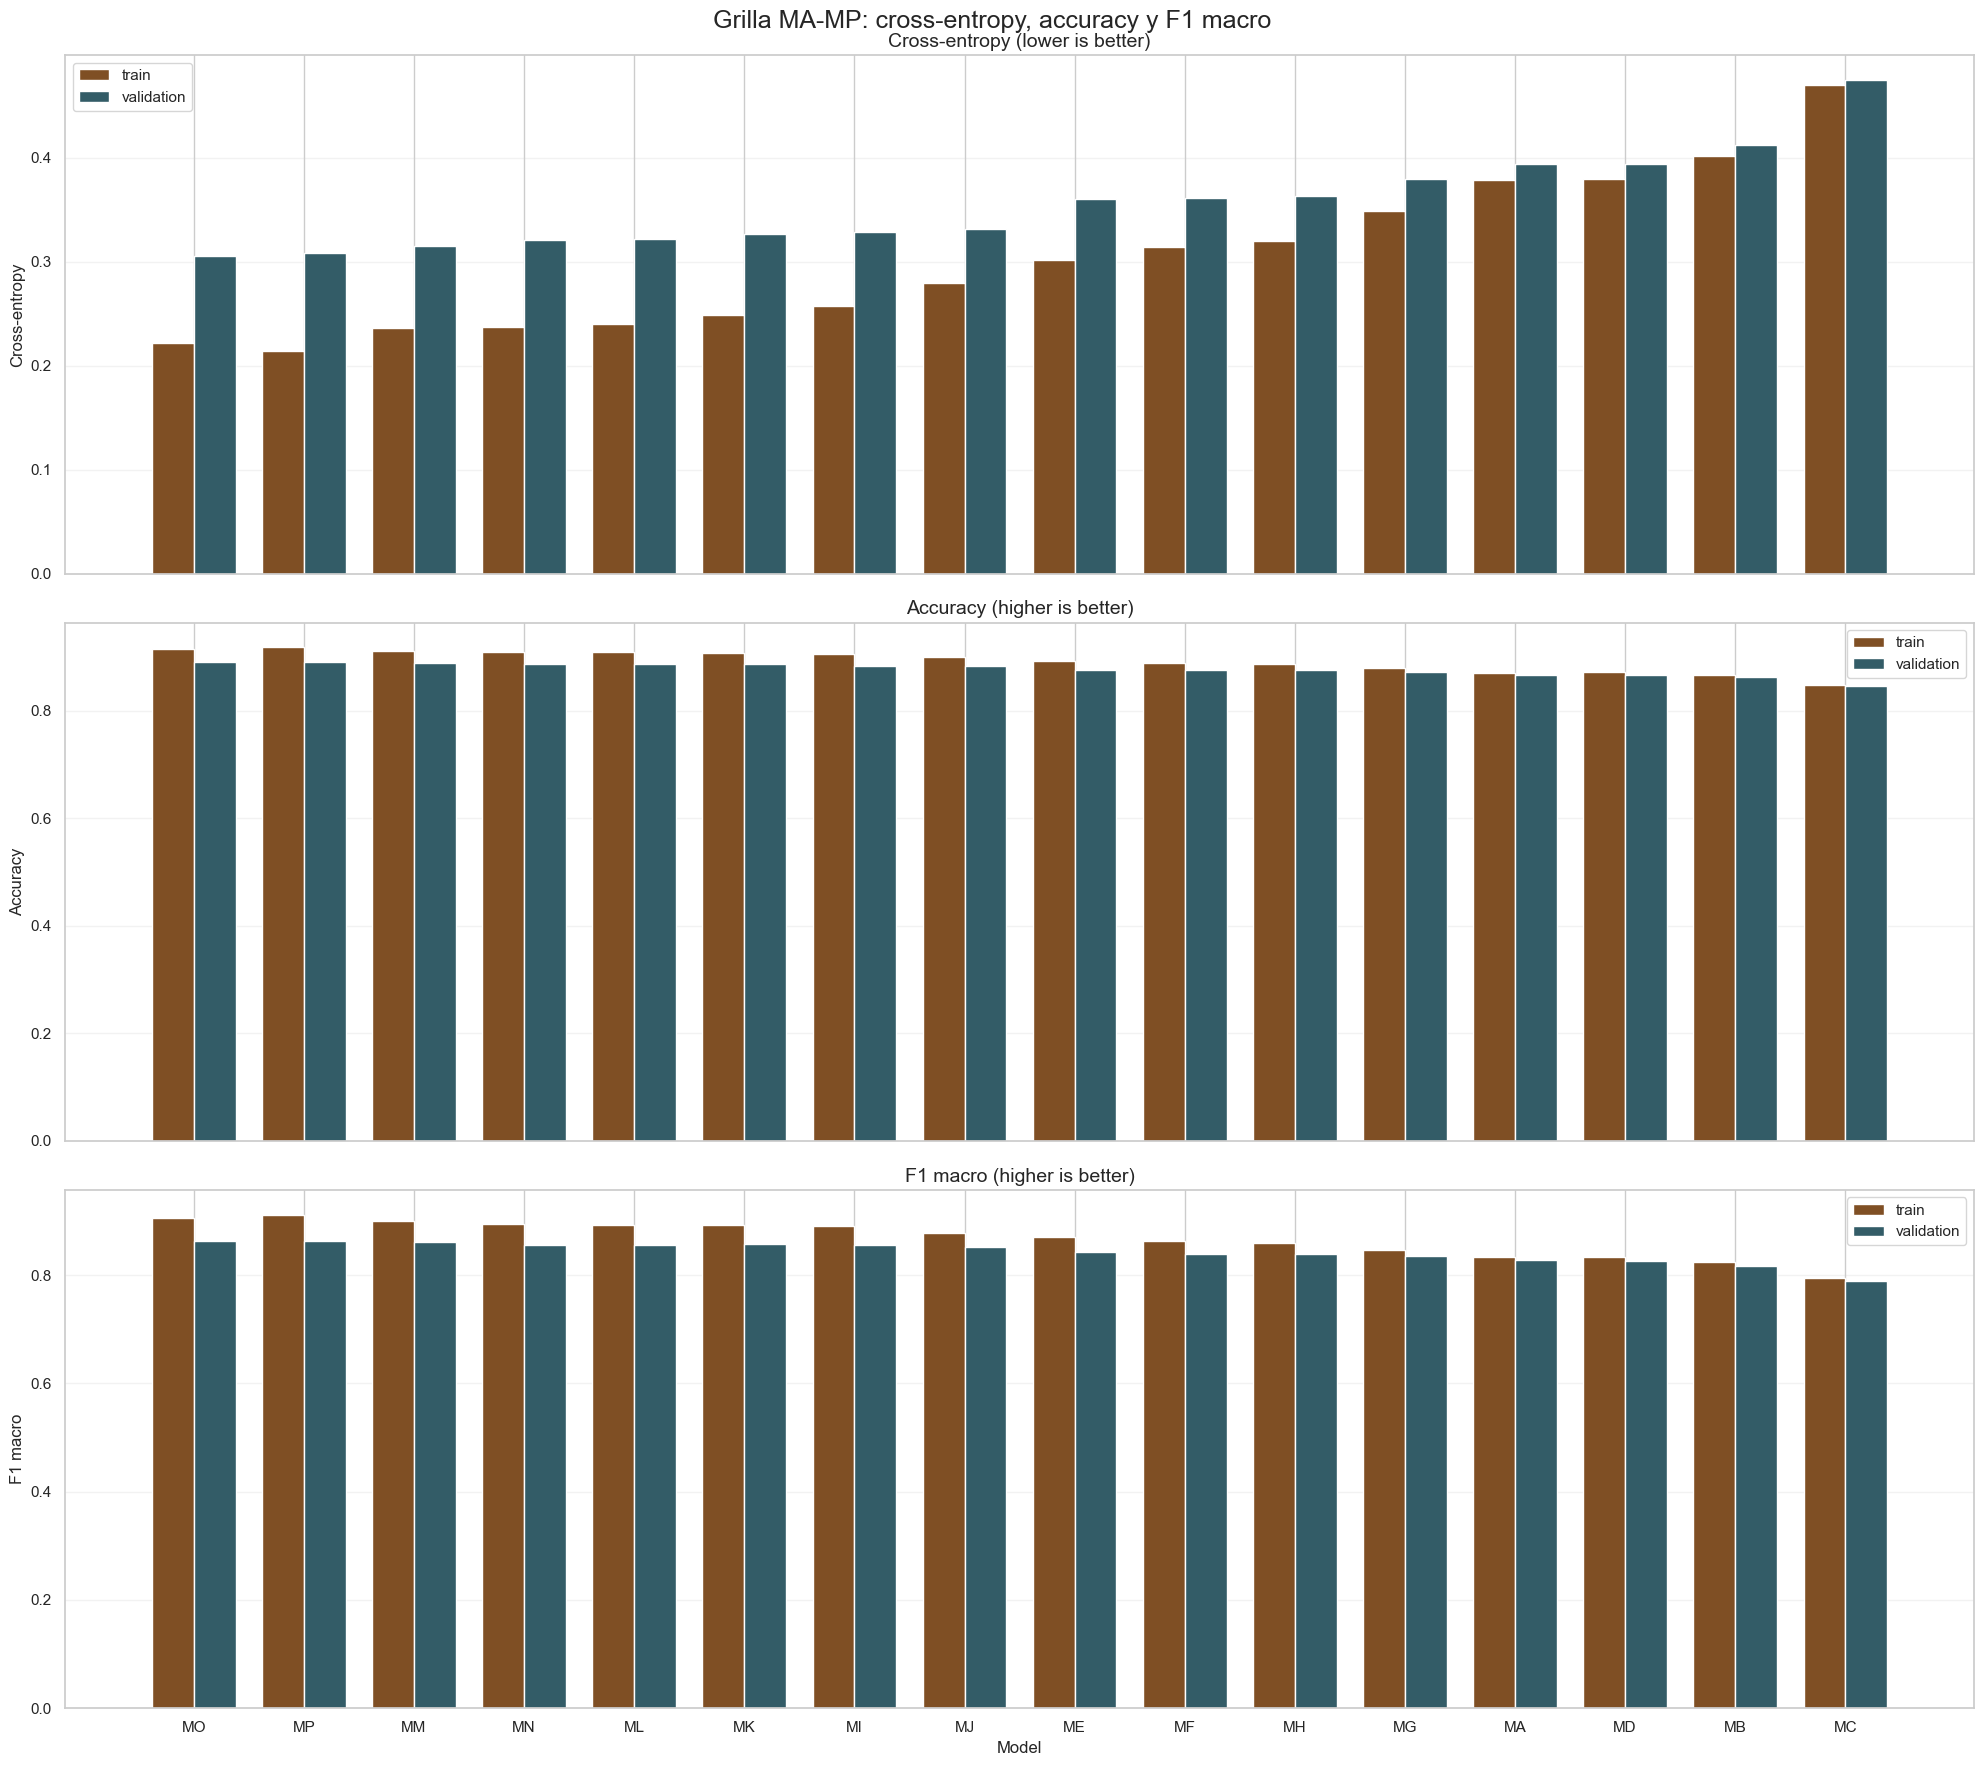

In [20]:
mostrar_titulo("Grafico 10", "Grilla MA-MP: Cross-Entropy, Accuracy y F1 Macro")
fig, _ = graficar_grilla_metrics(
    grid_summary,
    title="Grilla MA-MP: cross-entropy, accuracy y F1 macro",
)
plt.show()


**Lectura.** La grilla completa confirma que los mejores modelos estan en la familia `Adam + L2 + early stopping`, con arquitecturas mas grandes que el baseline. `MO` queda primero por `validation cross-entropy`, con `accuracy` y `F1 macro` altos. `MP` compite muy bien en `F1 macro`, pero usa mas parametros y no mejora el criterio principal. Por eso conviene pasar a una comparacion final entre candidatos, no decidir solo por una corrida.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 11 - Dashboard de Model Selection para M1</h3>

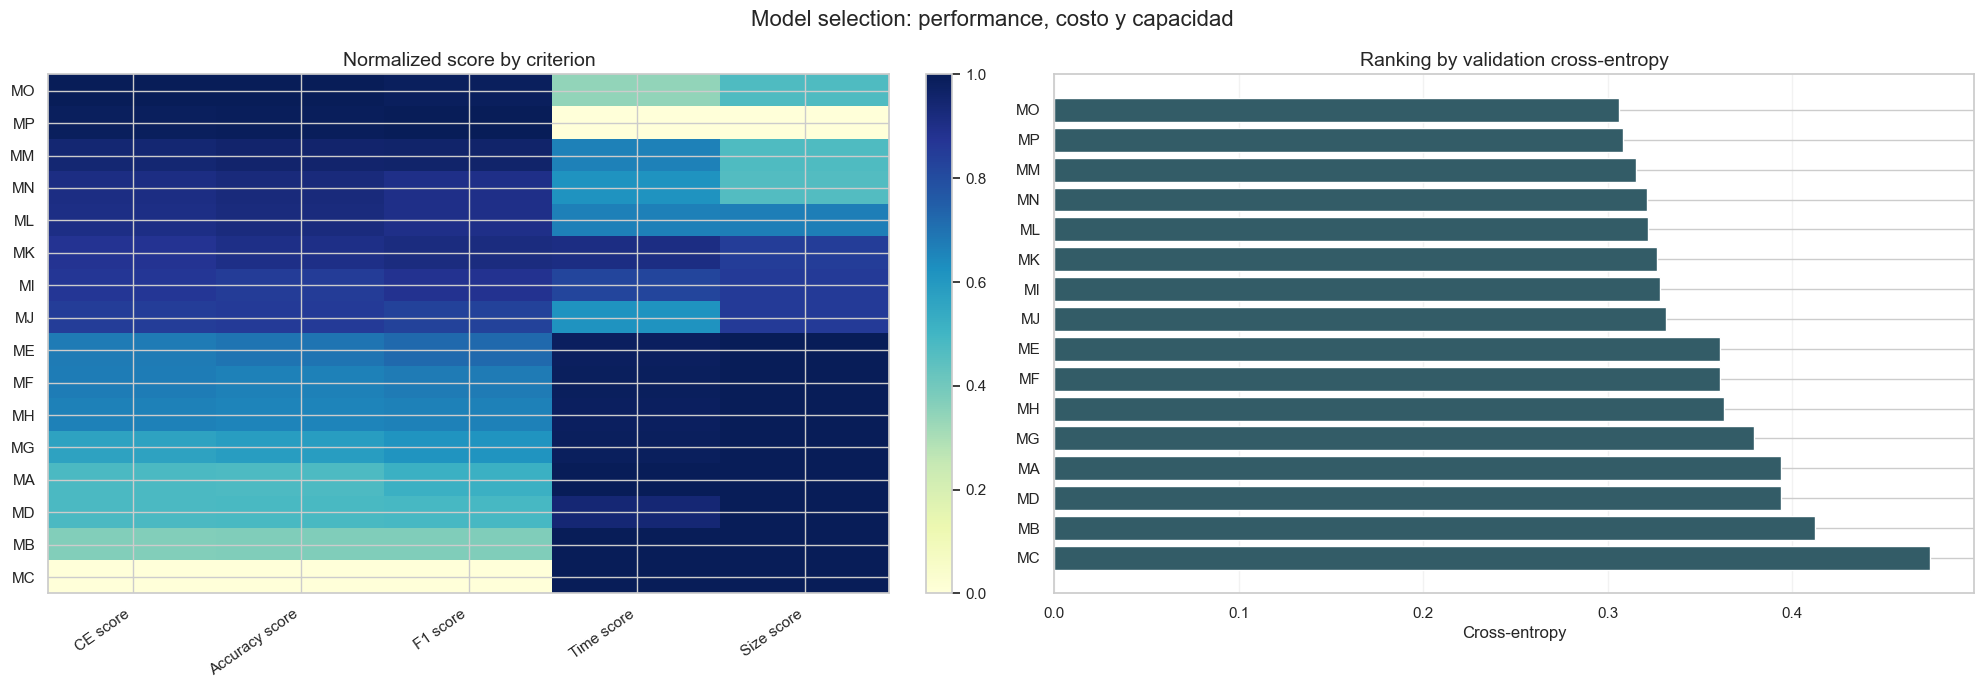

In [21]:
mostrar_titulo("Grafico 11", "Dashboard de Model Selection para M1")
fig, _ = graficar_dashboard_model_selection(
    grid_summary,
    title="Model selection: performance, costo y capacidad",
)
plt.show()


**Lectura.** El dashboard resume la seleccion sin llenar el grafico de etiquetas. `MO` aparece como el mejor balance entre `validation loss`, performance y tamano. `MP` queda cerca, pero es mas grande; `MM` funciona como otro candidato fuerte de la misma familia. Con esta lectura, los finalistas naturales son `MO`, `MP` y `MM`.


### Eleccion de M1

La primera grilla sirve para encontrar buenas familias, pero la decision final la hago con un criterio mas justo:

1. los finalistas tienen el mismo presupuesto maximo de `100` epochs;
2. el training usa `early stopping` clasico con `patience=10` sobre la mejor `validation cross-entropy`;
3. se restauran los pesos del mejor checkpoint de `validation`;
4. se elige principalmente por menor `validation cross-entropy`, usando `F1 macro` como desempate.

Con este esquema reentreno `MO`, `MP` y `MM`.


In [22]:
best_summary = pd.DataFrame([best_row])[
    [
        "model_id",
        "architecture",
        "optimizer",
        "schedule",
        "learning_rate",
        "final_lr",
        "l2_lambda",
        "completed_epochs",
        "validation_loss",
        "validation_accuracy",
        "validation_f1_macro",
        "parameter_count",
    ]
]

best_summary


,model_id,architecture,optimizer,schedule,learning_rate,final_lr,l2_lambda,completed_epochs,validation_loss,validation_accuracy,validation_f1_macro,parameter_count
14,MO,784-512-256-128-47,adam,linear,0.0010,0.0001,0.0001,35,0.3060,0.8910,0.8627,572207


In [23]:
FINALISTS_DIR = DIR_ARTIFACTS / "finalists_100"
FINALISTS_SUMMARY_PATH = FINALISTS_DIR / "finalists_100_summary.csv"

finalists_summary = pd.read_csv(FINALISTS_SUMMARY_PATH).sort_values("validation_loss")
print("Finalistas reentrenados a 100 epochs maximas: " + ", ".join(finalists_summary["model_id"].tolist()))


Finalistas reentrenados a 100 epochs maximas: MO, MP, MM


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 12 - Finalistas de M1 con Presupuesto de 100 Epochs</h3>

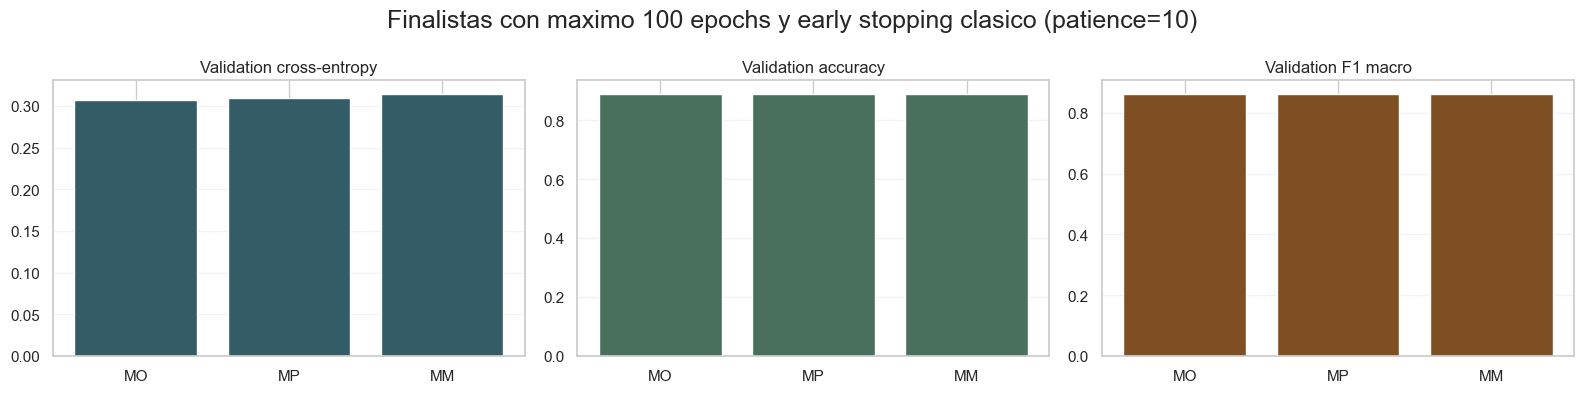

In [24]:
mostrar_titulo("Grafico 12", "Finalistas de M1 con Presupuesto de 100 Epochs")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
finalists_ordered = finalists_summary.sort_values("validation_loss")

axes[0].bar(finalists_ordered["model_id"], finalists_ordered["validation_loss"], color="#335c67")
axes[0].set_title("Validation cross-entropy")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(finalists_ordered["model_id"], finalists_ordered["validation_accuracy"], color="#496f5d")
axes[1].set_title("Validation accuracy")
axes[1].grid(axis="y", alpha=0.25)

axes[2].bar(finalists_ordered["model_id"], finalists_ordered["validation_f1_macro"], color="#7f4f24")
axes[2].set_title("Validation F1 macro")
axes[2].grid(axis="y", alpha=0.25)

fig.suptitle("Finalistas con maximo 100 epochs y early stopping clasico (patience=10)", fontsize=18)
fig.tight_layout()
plt.show()


**Lectura.** Con el mismo presupuesto maximo de `100` epochs, `MO` mantiene la mejor `validation cross-entropy` (`0.3070`). `MP` consigue un `F1 macro` apenas mayor, pero no mejora el criterio principal y ademas es mas grande. `MM` queda tercero. Por eso elijo `MO` como `M1`.


In [25]:
M1_HISTORY_PATH = DIR_ARTIFACTS / "m1_history.npz"
M1_METRICS_PATH = DIR_ARTIFACTS / "m1_metrics.npz"

history_m1_raw = cargar_historial(M1_HISTORY_PATH)
main_history_length = len(history_m1_raw["epoch"])
history_m1 = {
    key: value
    for key, value in history_m1_raw.items()
    if isinstance(value, list) and len(value) == main_history_length
}

m1_metrics = cargar_metrics(M1_METRICS_PATH)
print(f"M1 cargado desde artifacts: {len(history_m1['epoch'])} epochs registradas, mejor checkpoint restaurado.")


M1 cargado desde artifacts: 35 epochs registradas, mejor checkpoint restaurado.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 13 - M1: Cross-Entropy y Accuracy por Epoch</h3>

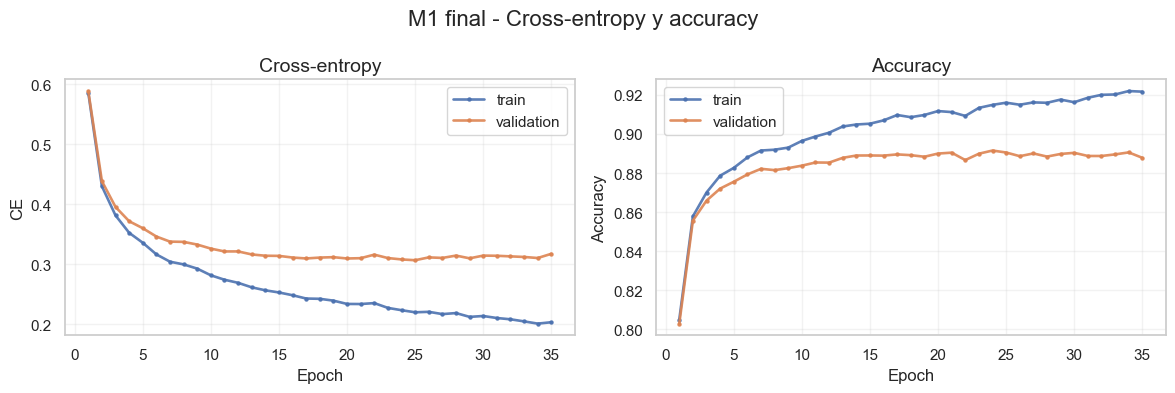

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 14 - M1: F1 Macro por Epoch</h3>

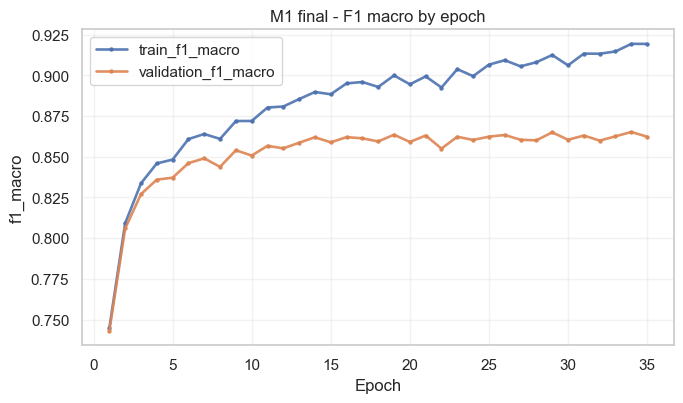

In [26]:
mostrar_titulo("Grafico 13", "M1: Cross-Entropy y Accuracy por Epoch")
fig, _ = graficar_loss_y_accuracy(history_m1, title="M1 final - Cross-entropy y accuracy")
plt.show()

mostrar_titulo("Grafico 14", "M1: F1 Macro por Epoch")
fig, _ = graficar_history_training(history_m1, metric="f1_macro")
plt.title("M1 final - F1 macro by epoch")
plt.show()


**Lectura.** `M1` aprende mucho mas rapido que `M0`. La mejor `validation cross-entropy` aparece en la epoch `25` (`0.3070`). Despues la curva de `train` sigue bajando, pero `validation` empieza a empeorar. Esa separacion marca overfitting y justifica el uso de `early stopping` con restauracion del mejor checkpoint.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 15 - Training Diagnostics de M1</h3>

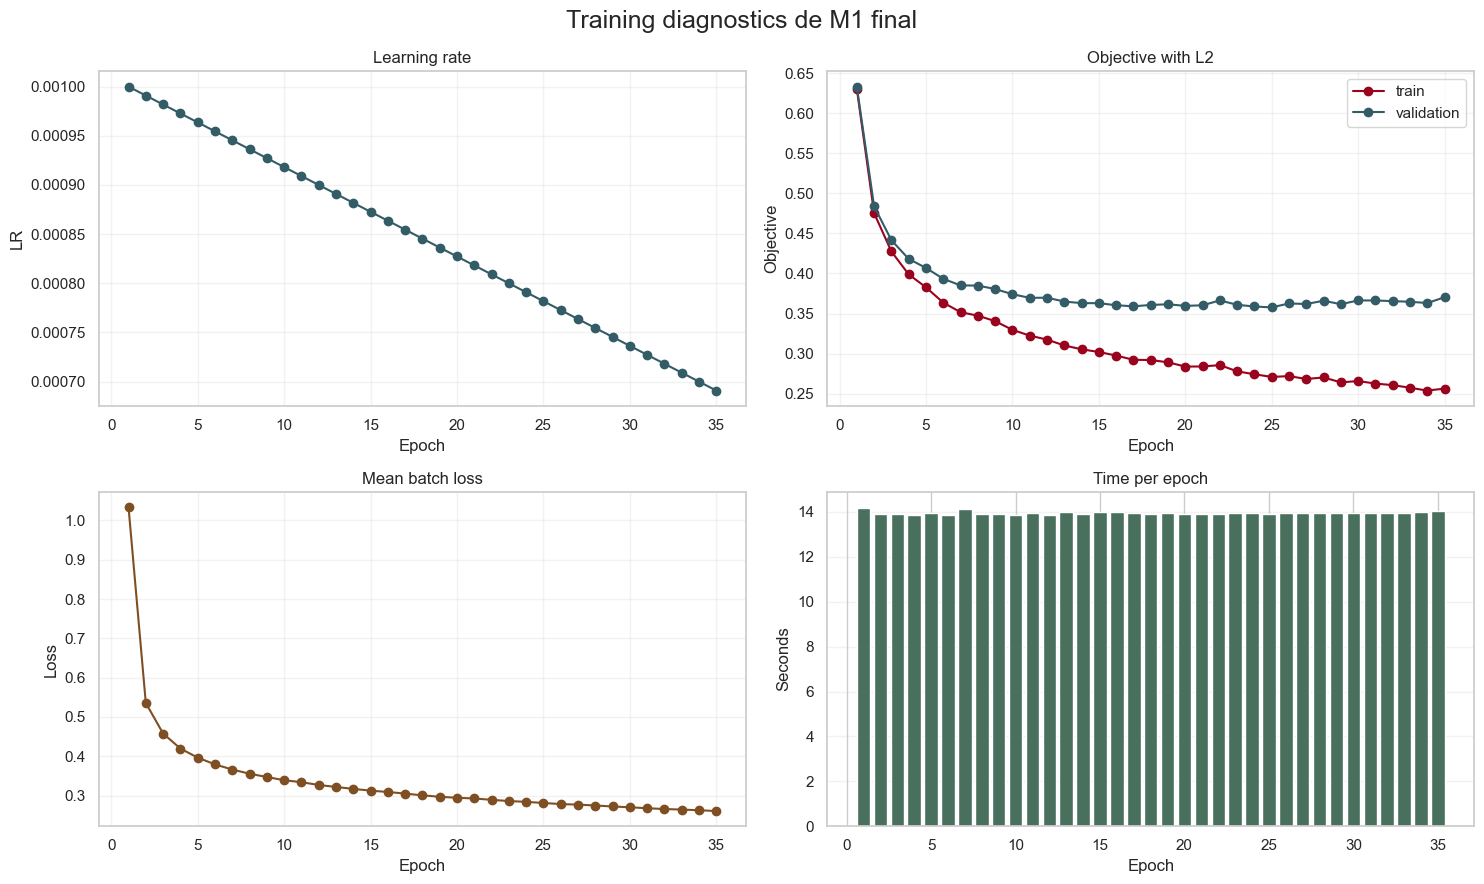

In [27]:
mostrar_titulo("Grafico 15", "Training Diagnostics de M1")
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].plot(history_m1["epoch"], history_m1["learning_rate"], marker="o", color="#335c67")
axes[0, 0].set_title("Learning rate")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("LR")
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(history_m1["epoch"], history_m1["train_objective"], marker="o", color="#9a031e", label="train")
axes[0, 1].plot(history_m1["epoch"], history_m1["validation_objective"], marker="o", color="#335c67", label="validation")
axes[0, 1].set_title("Objective with L2")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Objective")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(history_m1["epoch"], history_m1["mean_batch_loss"], marker="o", color="#7f4f24")
axes[1, 0].set_title("Mean batch loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].grid(alpha=0.25)

axes[1, 1].bar(history_m1["epoch"], history_m1["elapsed_seconds"], color="#496f5d")
axes[1, 1].set_title("Time per epoch")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Seconds")
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle("Training diagnostics de M1 final", fontsize=18)
fig.tight_layout()
plt.show()


**Lectura.** El `learning rate` baja de forma lineal desde `0.001`. La norma media del gradiente cae fuerte al comienzo y despues se estabiliza, lo cual sugiere que el training deja de hacer cambios bruscos. El tiempo por epoch se mantiene bastante estable, alrededor de `14` segundos, consistente con una arquitectura y un dataset fijos.


In [28]:
m1_metrics_table = pd.DataFrame(
    [
        {
            "modelo": "M1",
            "split": "train",
            "accuracy": float(m1_metrics["train_accuracy"]),
            "cross_entropy": float(m1_metrics["train_loss"]),
            "f1_macro": float(m1_metrics["train_f1_macro"]),
        },
        {
            "modelo": "M1",
            "split": "validation",
            "accuracy": float(m1_metrics["validation_accuracy"]),
            "cross_entropy": float(m1_metrics["validation_loss"]),
            "f1_macro": float(m1_metrics["validation_f1_macro"]),
        },
    ]
)

comparison_m0_m1 = pd.concat(
    [
        m0_metrics_table[["modelo", "split", "accuracy", "cross_entropy", "f1_macro"]],
        m1_metrics_table[["modelo", "split", "accuracy", "cross_entropy", "f1_macro"]],
    ],
    ignore_index=True,
)


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 16 - Comparacion M0 vs M1 en Validation</h3>

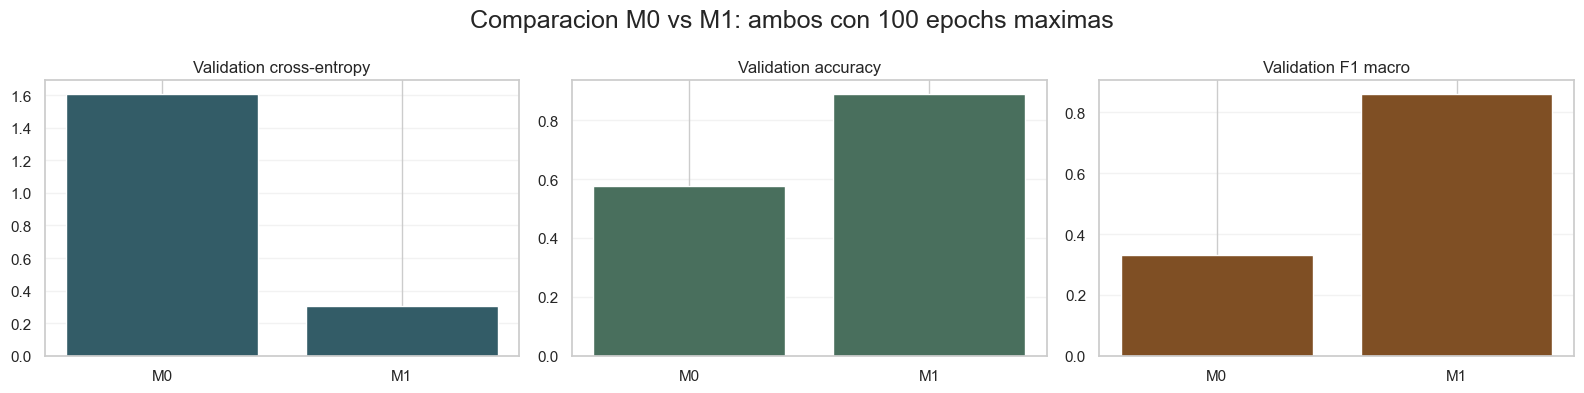

In [29]:
mostrar_titulo("Grafico 16", "Comparacion M0 vs M1 en Validation")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
validation_comparison = comparison_m0_m1[comparison_m0_m1["split"] == "validation"].reset_index(drop=True)

axes[0].bar(validation_comparison["modelo"], validation_comparison["cross_entropy"], color="#335c67")
axes[0].set_title("Validation cross-entropy")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(validation_comparison["modelo"], validation_comparison["accuracy"], color="#496f5d")
axes[1].set_title("Validation accuracy")
axes[1].grid(axis="y", alpha=0.25)

axes[2].bar(validation_comparison["modelo"], validation_comparison["f1_macro"], color="#7f4f24")
axes[2].set_title("Validation F1 macro")
axes[2].grid(axis="y", alpha=0.25)

fig.suptitle("Comparacion M0 vs M1: ambos con 100 epochs maximas", fontsize=18)
fig.tight_layout()
plt.show()


**Lectura.** La comparacion `M0` vs `M1` muestra una mejora muy grande: `validation cross-entropy` baja de `1.609` a `0.307`, `accuracy` sube de `0.577` a `0.891` y `F1 macro` pasa de `0.333` a `0.862`. La mejora en `F1 macro` es especialmente importante porque indica que el avance no se limita a las clases mas frecuentes.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 17 - M1: Confusion Diagnostics en Validation</h3>

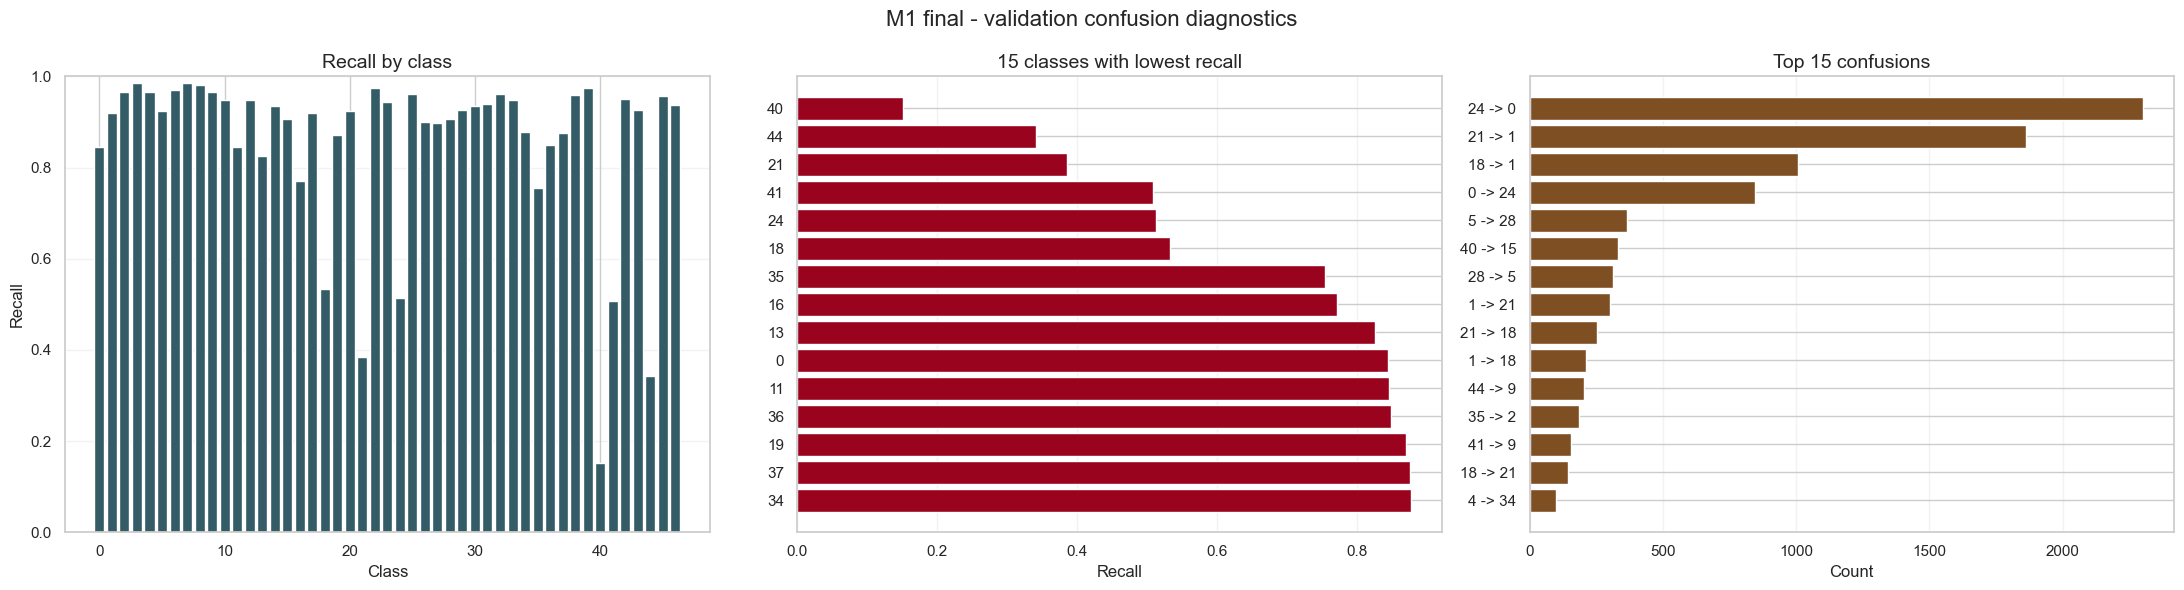

In [30]:
mostrar_titulo("Grafico 17", "M1: Confusion Diagnostics en Validation")
fig, axes, m1_per_class, m1_top_confusions = graficar_confusion_diagnostics(
    m1_metrics["validation_confusion_matrix"],
    top_n=15,
    title="M1 final - validation confusion diagnostics",
)
plt.show()


**Lectura.** `M1` corrige gran parte de los errores de `M0`, aunque no elimina todos los casos dificiles. Siguen apareciendo clases con recall mas bajo, como `40`, `44`, `21`, `24` y `18`. Tambien persisten confusiones como `24 -> 0`, `21 -> 1` y `18 -> 1`, probablemente porque son caracteres visualmente parecidos.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 18 - M1: Normalized Confusion Matrix en Validation</h3>

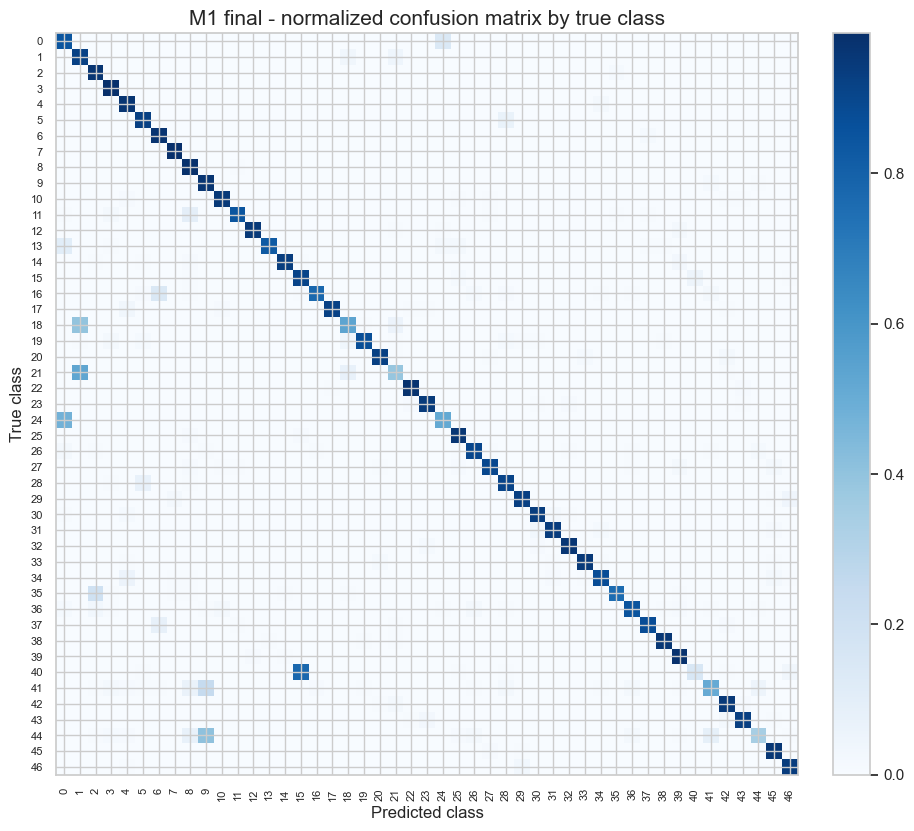

In [31]:
mostrar_titulo("Grafico 18", "M1: Normalized Confusion Matrix en Validation")
fig, _ = graficar_confusion_matrix(
    m1_metrics["validation_confusion_matrix"],
    title="M1 final - normalized confusion matrix by true class",
    normalizar=True,
    annotate=False,
)
fig.set_size_inches(10, 9)
plt.show()


**Lectura.** En `M1` la diagonal de la `confusion matrix` queda mucho mas marcada que en `M0`. Eso muestra reconocimiento mas consistente en la mayoria de las clases. Los errores ahora se concentran mas en algunos pares dificiles, en lugar de estar tan dispersos como en el baseline.


**Cierre del punto 3.** La eleccion de `M1` no sale de una prueba aislada. Primero uso una grilla amplia para encontrar familias prometedoras; despues reentreno finalistas bajo el mismo presupuesto y con el mismo criterio de corte. `MO` queda como `M1` porque logra la menor `validation cross-entropy`, mantiene buen `F1 macro` y no paga el costo extra de `MP`.


## Punto 4 - PyTorch, M2, M3 y robustez

En este punto paso de NumPy a PyTorch. Primero entreno `M2`, que replica la arquitectura y los hiperparametros principales de `M1`. Eso sirve para validar que el comportamiento no cambie solo por el framework.

Despues uso PyTorch para explorar un pool mas amplio, porque ahi es mas comodo probar `BatchNorm`, `Dropout`, activaciones modernas y `AdamW`. La idea es que la mejora de `M3` venga de mejores decisiones de arquitectura/training, no simplemente de cambiar de libreria.

Para cada layer:

$$a^{[l]} = Z^{[l-1]} W^{[l]} + b^{[l]}$$

$$Z^{[l]} = g(a^{[l]})$$

donde `g` puede ser `ReLU`, `LeakyReLU`, `SiLU`/`Swish` o `GELU`. En la ultima layer, PyTorch devuelve logits y `CrossEntropyLoss` aplica internamente `softmax`:

$$p_{i,c} = \frac{e^{a_{i,c}}}{\sum_j e^{a_{i,j}}}, \qquad
CE = -\frac{1}{N}\sum_{i=1}^{N}\log(p_{i,y_i})$$


In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import Markdown, display

from src.data import cargar_arrays_emnist, indices_split_estratificado
from src.torch_training import learning_rate_para_epoch
from src.plots import (
    graficar_confusion_diagnostics,
    graficar_confusion_matrix,
    graficar_comparacion_modelos_finales,
    graficar_loss_y_accuracy,
    graficar_grilla_metrics,
    graficar_robustness_noise,
    graficar_history_training,
)

DIR_ARTIFACTS = Path("artifacts")

if "X_imagenes" not in globals() or "y_imagenes" not in globals():
    X_imagenes, y_imagenes = cargar_arrays_emnist(mmap_mode="r")
if "particiones" not in globals():
    particiones = indices_split_estratificado(y_imagenes, random_state=42)


def cargar_historial_npz(path):
    data = np.load(path, allow_pickle=True)
    return {key: data[key].tolist() for key in data.files}


def limpiar_float_opcional(value):
    if value is None or pd.isna(value):
        return None
    return float(value)


In [33]:
point4_artifacts = [
    DIR_ARTIFACTS / "m2_history.npz",
    DIR_ARTIFACTS / "m2_metrics.npz",
    DIR_ARTIFACTS / "torch_grid_v1_experiment_summary.csv",
    DIR_ARTIFACTS / "m3_history.npz",
    DIR_ARTIFACTS / "m3_metrics.npz",
    DIR_ARTIFACTS / "point4_test_summary.csv",
    DIR_ARTIFACTS / "point4_noise_robustness.csv",
    DIR_ARTIFACTS / "point4_test_confusion_matrices.npz",
]

artifact_check = pd.DataFrame(
    {
        "artifact": [str(path) for path in point4_artifacts],
        "existe": [path.exists() for path in point4_artifacts],
    }
)

missing_artifacts = artifact_check.loc[~artifact_check["existe"], "artifact"].tolist()
if missing_artifacts:
    print("Faltan artifacts compactos para ejecutar el notebook:")
    for artifact in missing_artifacts:
        print(f"- {artifact}")
else:
    print(f"Artifacts compactos del punto 4 verificados: {len(point4_artifacts)} archivos disponibles.")


Artifacts compactos del punto 4 verificados: 8 archivos disponibles.


**Nota de reproducibilidad.** Los entrenamientos pesados del punto 4 ya estan guardados en `artifacts/`. El notebook usa esos resultados compactos para mostrar graficos y tablas sin volver a entrenar. Si falta algun archivo, la celda de chequeo lo informa.


### 4.a - M2 equivalente a M1 en PyTorch

`M2` replica la familia elegida para `M1`: arquitectura `784-512-256-128-47`, activacion `ReLU`, optimizer `Adam`, `weight_decay=5e-5`, `linear learning rate schedule` y maximo de `100` epochs.

Esta comparacion responde una pregunta concreta: si mantengo casi todo igual, PyTorch reproduce el resultado de mi implementacion en NumPy?


In [34]:
m1_metrics_np = np.load(DIR_ARTIFACTS / "m1_metrics.npz")
m2_metrics_np = np.load(DIR_ARTIFACTS / "m2_metrics.npz")
m1_m2_validation = pd.DataFrame(
    [
        {
            "model_id": "M1",
            "framework": "NumPy",
            "validation_loss": float(m1_metrics_np["validation_loss"]),
            "validation_accuracy": float(m1_metrics_np["validation_accuracy"]),
            "validation_f1_macro": float(m1_metrics_np["validation_f1_macro"]),
        },
        {
            "model_id": "M2",
            "framework": "PyTorch",
            "validation_loss": float(m2_metrics_np["validation_loss"]),
            "validation_accuracy": float(m2_metrics_np["validation_accuracy"]),
            "validation_f1_macro": float(m2_metrics_np["validation_f1_macro"]),
        },
    ]
)

print(
    "Comparacion M1/M2 cargada: "
    f"M1 CE={m1_m2_validation.loc[0, 'validation_loss']:.4f}, "
    f"M2 CE={m1_m2_validation.loc[1, 'validation_loss']:.4f}."
)


Comparacion M1/M2 cargada: M1 CE=0.3070, M2 CE=0.3079.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 19 - M2 PyTorch: Cross-Entropy y Accuracy por Epoch</h3>

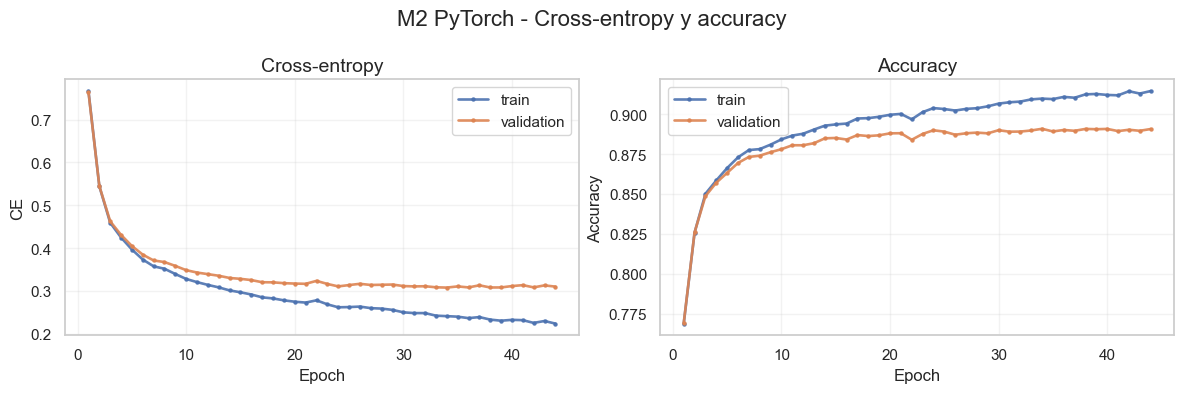

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 20 - M2 PyTorch: F1 Macro por Epoch</h3>

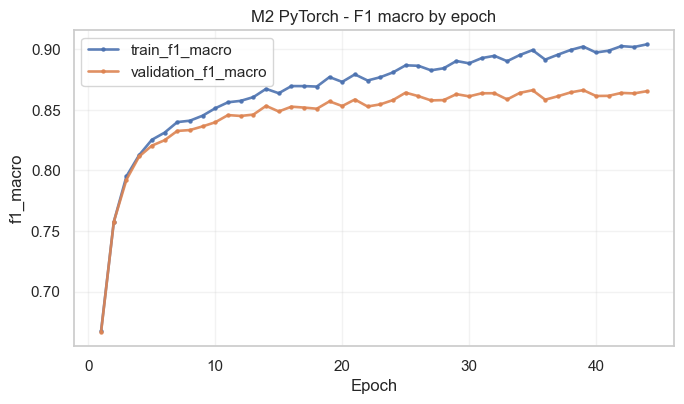

In [35]:
history_m2 = cargar_historial_npz(DIR_ARTIFACTS / "m2_history.npz")

mostrar_titulo("Grafico 19", "M2 PyTorch: Cross-Entropy y Accuracy por Epoch")
fig, _ = graficar_loss_y_accuracy(history_m2, title="M2 PyTorch - Cross-entropy y accuracy")
plt.show()

mostrar_titulo("Grafico 20", "M2 PyTorch: F1 Macro por Epoch")
fig, _ = graficar_history_training(history_m2, metric="f1_macro")
plt.title("M2 PyTorch - F1 macro by epoch")
plt.show()


**Lectura.** `M2` reproduce muy bien a `M1`. Su mejor `validation cross-entropy` queda en `0.3079`, practicamente igual a la de `M1` (`0.3070`), y el `F1 macro` tambien queda muy cerca. Entonces, el cambio de framework por si solo no explica una mejora grande. Para mejorar de verdad hay que usar PyTorch para explorar mejores arquitecturas y regularizacion.


### 4.b - Model pool de PyTorch para elegir M3

El pool `P4A`-`P4T` explora varias combinaciones:

- activaciones: `ReLU`, `LeakyReLU`, `SiLU`/`Swish` y `GELU`;
- regularizacion: `weight_decay`, `BatchNorm`, `Dropout` y `label_smoothing`;
- optimizers: `Adam` y `AdamW`;
- arquitecturas de 3 y 4 hidden layers, desde `512-256-128` hasta `1024-512-256-128`;
- schedules `linear` y `cosine`.

Todos los candidatos del pool tienen un presupuesto comparable. Despues, el mejor candidato se reentrena como `M3` con `100` epochs maximas y `early stopping`.


In [36]:
torch_grid_summary = pd.read_csv(DIR_ARTIFACTS / "torch_grid_v1_experiment_summary.csv")
torch_grid_ordered = torch_grid_summary.sort_values("validation_loss").reset_index(drop=True)

print(
    f"Pool PyTorch cargado: {len(torch_grid_summary)} candidatos P4A-P4T con activaciones, "
    "BatchNorm, Dropout, Adam/AdamW, schedules y distintas capacidades."
)


Pool PyTorch cargado: 20 candidatos P4A-P4T con activaciones, BatchNorm, Dropout, Adam/AdamW, schedules y distintas capacidades.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 21 - PyTorch Model Pool P4A-P4T: Main Metrics</h3>

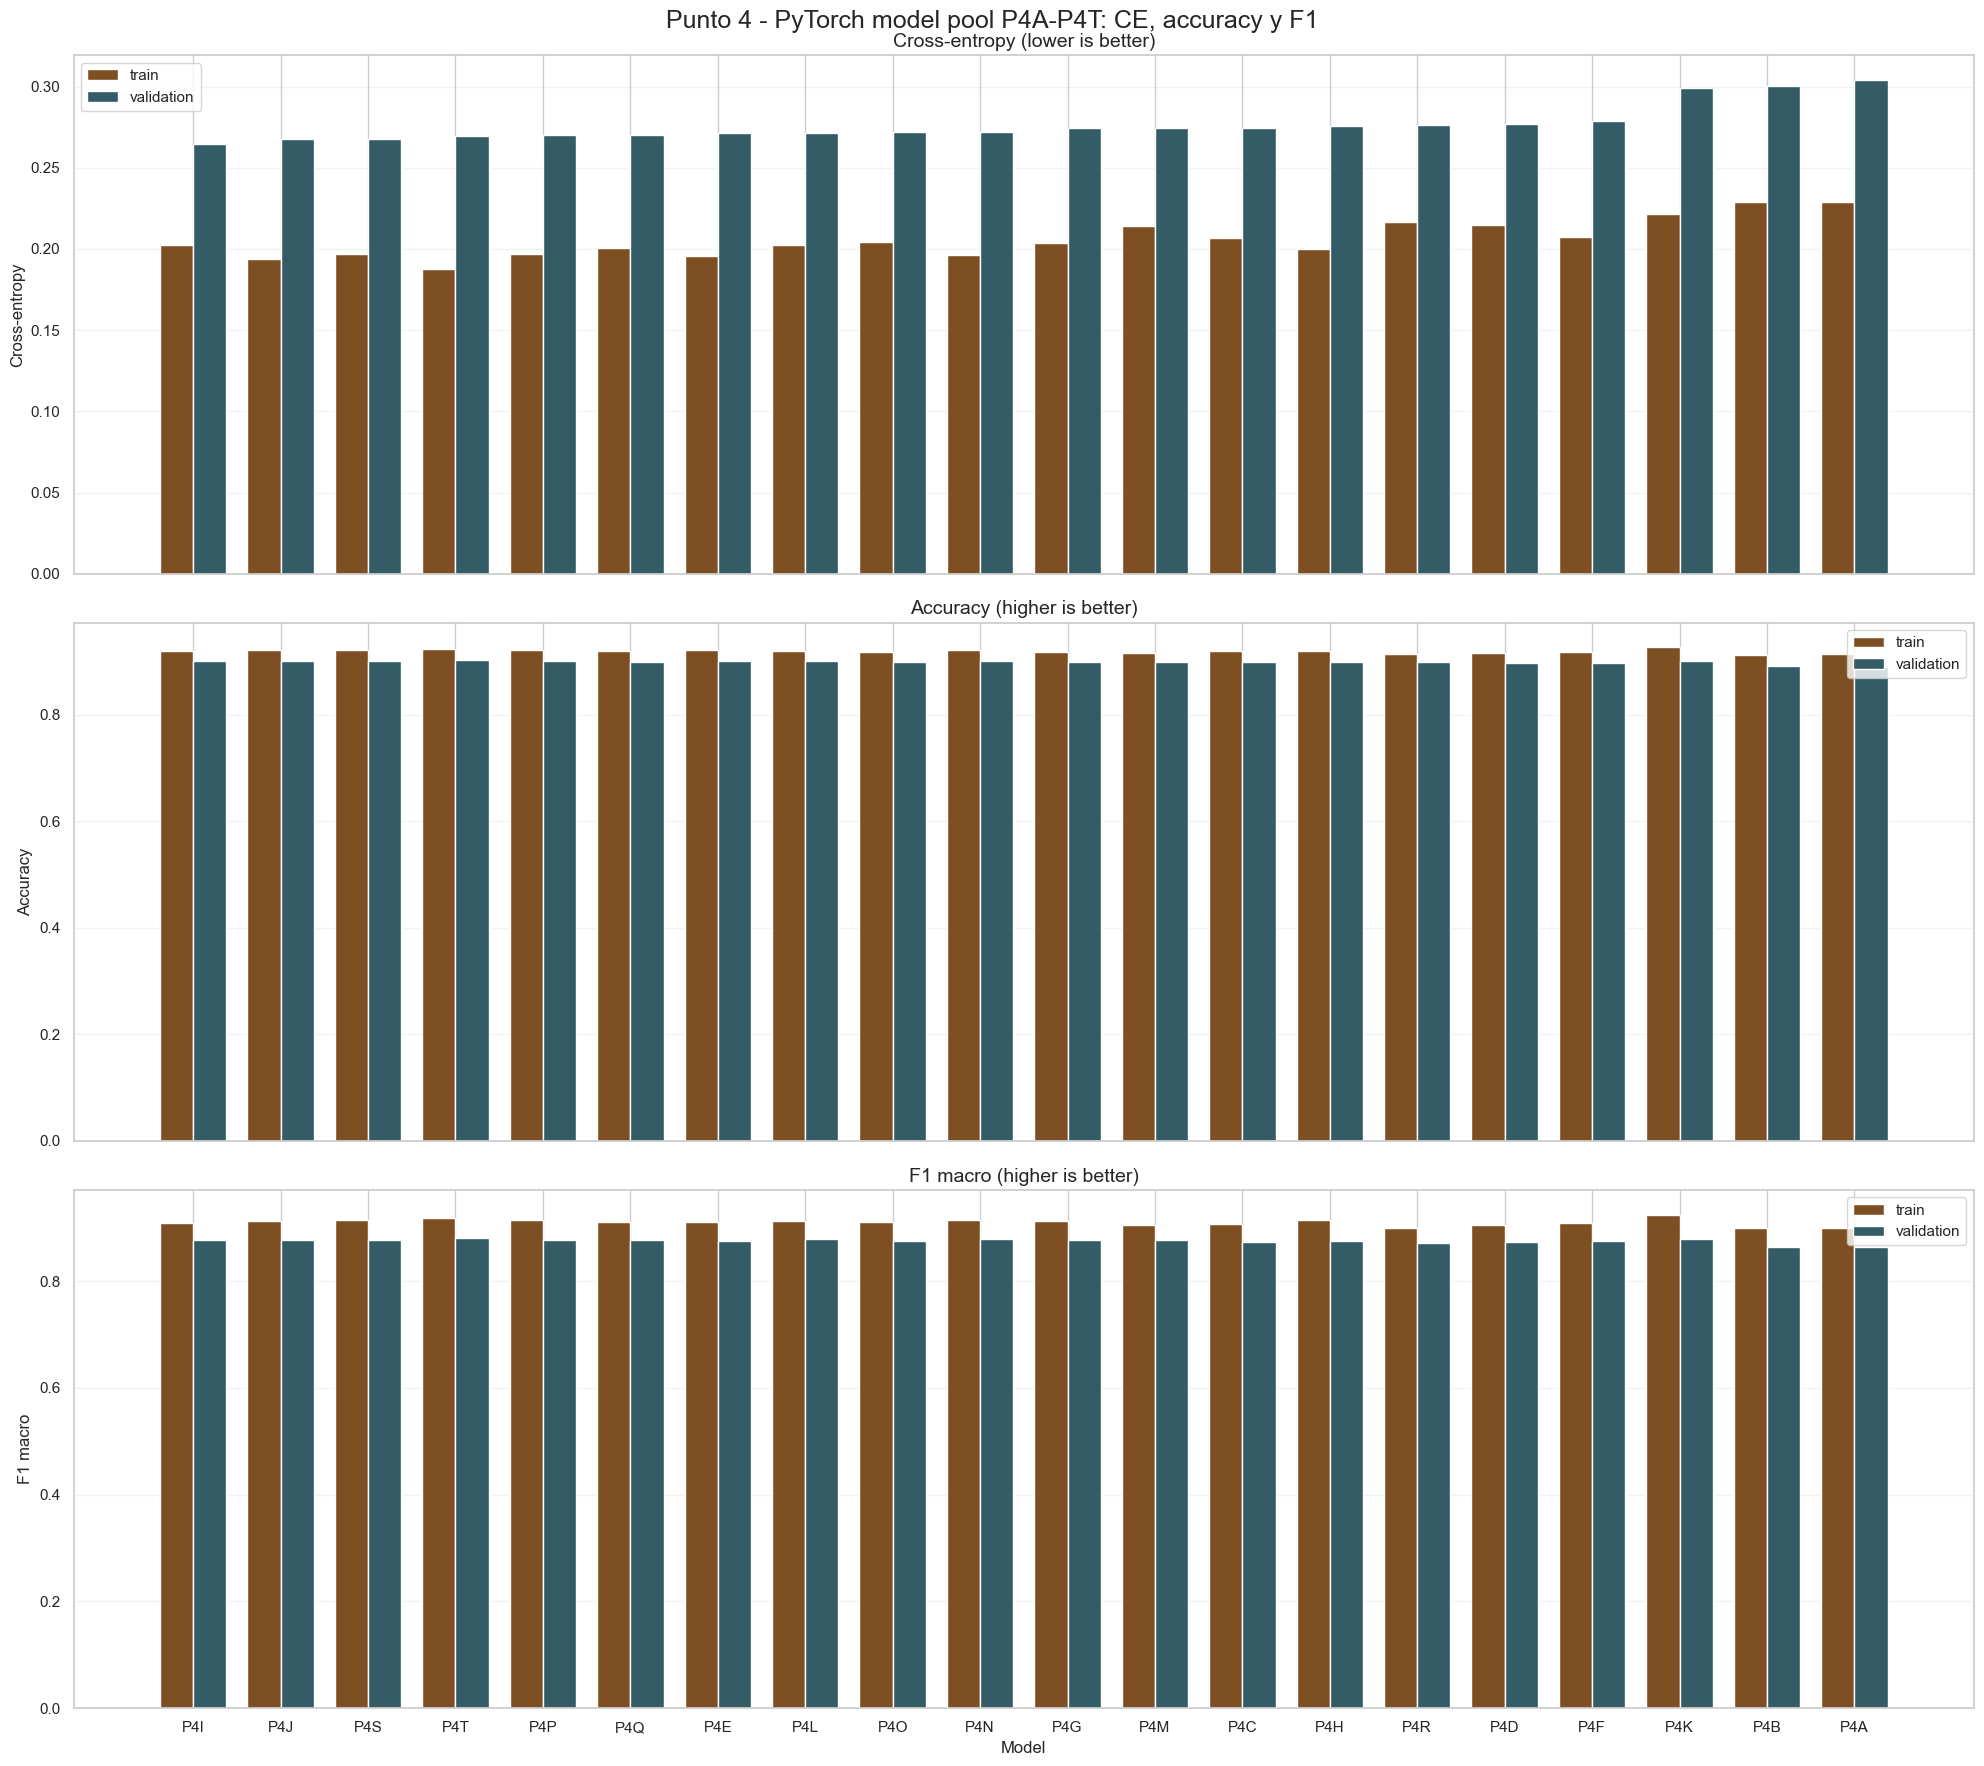

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 22 - Dashboard de Model Selection para M3</h3>

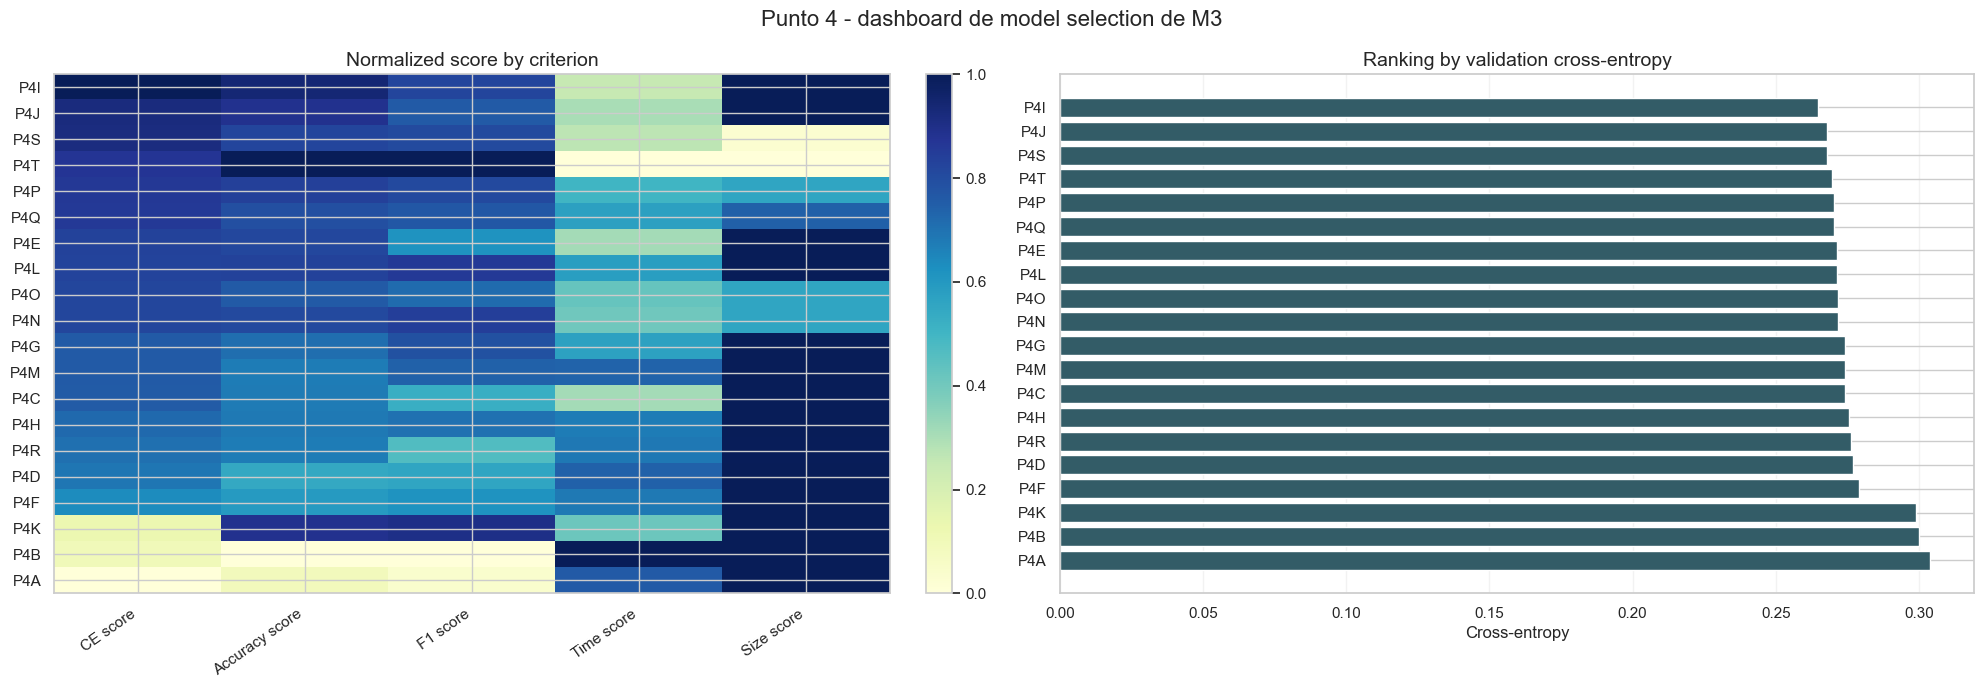

In [37]:
mostrar_titulo("Grafico 21", "PyTorch Model Pool P4A-P4T: Main Metrics")
fig, _ = graficar_grilla_metrics(
    torch_grid_summary,
    title="Punto 4 - PyTorch model pool P4A-P4T: CE, accuracy y F1",
)
plt.show()

mostrar_titulo("Grafico 22", "Dashboard de Model Selection para M3")
fig, _ = graficar_dashboard_model_selection(
    torch_grid_summary,
    title="Punto 4 - dashboard de model selection de M3",
)
plt.show()


**Lectura.** El pool PyTorch muestra que las mejores combinaciones usan `BatchNorm` y `Dropout`, junto con activaciones suaves como `SiLU` o `GELU`. El mejor candidato por `validation cross-entropy` es `P4I`, con `CE=0.2647`, `accuracy=0.9019` y `F1 macro=0.8779`. `P4T` logra un `F1 macro` levemente mayor, pero con peor `cross-entropy` y una arquitectura mas grande. Por el criterio principal, `P4I` se promueve a `M3`.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 23 - Learning Rate Schedules del Top 8 PyTorch</h3>

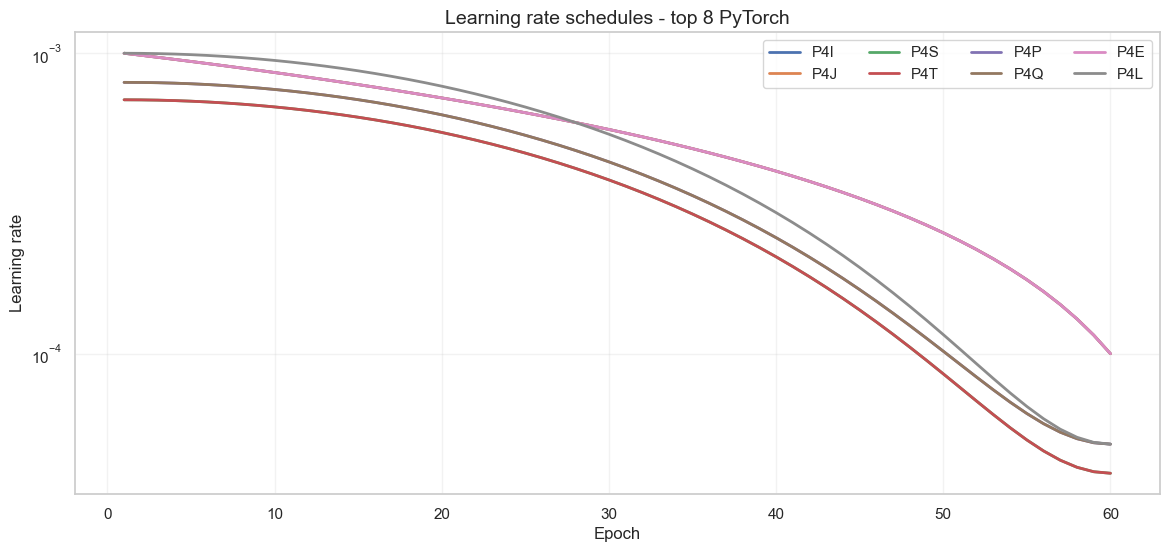

In [38]:
mostrar_titulo("Grafico 23", "Learning Rate Schedules del Top 8 PyTorch")
top_schedule_ids = torch_grid_ordered.head(8)["model_id"].tolist()

fig, ax = plt.subplots(figsize=(14, 6))
for model_id in top_schedule_ids:
    config = torch_grid_summary.loc[torch_grid_summary["model_id"] == model_id].iloc[0]
    epochs = np.arange(1, int(config["epochs"]) + 1)
    lrs = [
        learning_rate_para_epoch(
            int(epoch),
            initial_lr=float(config["learning_rate"]),
            schedule=config["schedule"],
            total_epochs=int(config["epochs"]),
            final_lr=limpiar_float_opcional(config["final_lr"]),
            decay_rate=limpiar_float_opcional(config["decay_rate"]),
            min_lr=limpiar_float_opcional(config["min_lr"]),
        )
        for epoch in epochs
    ]
    ax.plot(epochs, lrs, linewidth=2, label=model_id)

ax.set_title("Learning rate schedules - top 8 PyTorch", fontsize=14)
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend(ncol=4)
plt.show()


**Lectura.** Los `learning rate schedules` de los mejores candidatos se comparan sobre las mismas `60` epochs. Los schedules lineales bajan de manera uniforme; los schedules coseno concentran mas la caida hacia el final. Esta comparacion ayuda a verificar que los modelos finalistas no solo difieren en arquitectura, sino tambien en dinamica de training.


In [39]:
best_torch_row = torch_grid_summary.sort_values(
    ["validation_loss", "validation_f1_macro", "validation_accuracy"],
    ascending=[True, False, False],
).iloc[0]
m3_metrics_np = np.load(DIR_ARTIFACTS / "m3_metrics.npz")

m3_choice_table = pd.DataFrame(
    [
        {
            "modelo_pool": best_torch_row["model_id"],
            "arquitectura": best_torch_row["hidden_sizes"],
            "activacion": best_torch_row["activation"],
            "dropout": best_torch_row["dropout"],
            "batch_norm": best_torch_row["batch_norm"],
            "optimizer": best_torch_row["optimizer"],
            "schedule": best_torch_row["schedule"],
            "CE_val_pool": best_torch_row["validation_loss"],
            "F1_val_pool": best_torch_row["validation_f1_macro"],
            "modelo_final": "M3",
            "CE_val_M3": float(m3_metrics_np["validation_loss"]),
            "accuracy_val_M3": float(m3_metrics_np["validation_accuracy"]),
            "F1_val_M3": float(m3_metrics_np["validation_f1_macro"]),
        }
    ]
)

m3_choice_table


,modelo_pool,arquitectura,activacion,dropout,batch_norm,optimizer,schedule,CE_val_pool,F1_val_pool,modelo_final,CE_val_M3,accuracy_val_M3,F1_val_M3
0,P4I,512-256-128,silu,0.2000,True,adam,linear,0.2647,0.8779,M3,0.2665,0.9009,0.8763


**Lectura.** La tabla resume la decision: `P4I` es el mejor modelo del pool por `validation cross-entropy` y se reentrena como `M3`. El `M3` final queda con `validation CE=0.2665`, `accuracy=0.9009` y `F1 macro=0.8763`. Mantiene una ventaja clara frente a `M1/M2` sin saltar a la arquitectura mas grande del pool.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 24 - M3 final: Cross-Entropy y Accuracy por Epoch</h3>

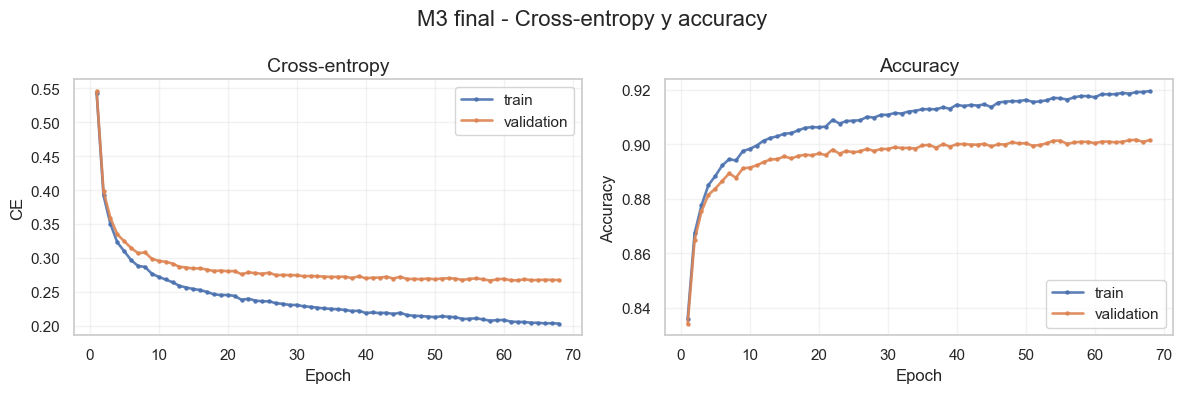

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 25 - M3 final: F1 Macro por Epoch</h3>

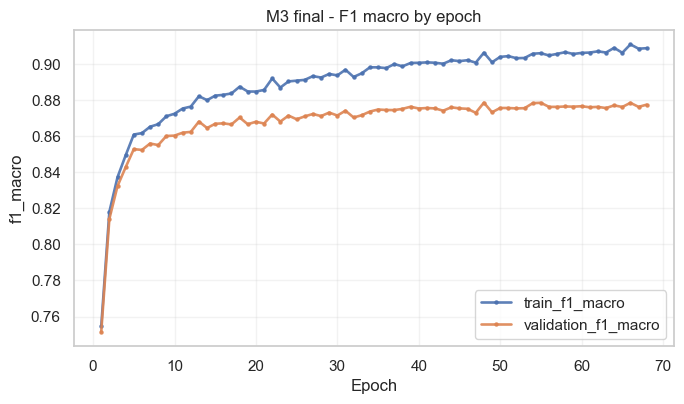

In [40]:
history_m3 = cargar_historial_npz(DIR_ARTIFACTS / "m3_history.npz")

mostrar_titulo("Grafico 24", "M3 final: Cross-Entropy y Accuracy por Epoch")
fig, _ = graficar_loss_y_accuracy(history_m3, title="M3 final - Cross-entropy y accuracy")
plt.show()

mostrar_titulo("Grafico 25", "M3 final: F1 Macro por Epoch")
fig, _ = graficar_history_training(history_m3, metric="f1_macro")
plt.title("M3 final - F1 macro by epoch")
plt.show()


**Lectura.** `M3` combina mejor ajuste y mejor generalizacion que los modelos anteriores. La mejor `validation cross-entropy` aparece en la epoch `58`; despues el training se detiene por `early stopping` clasico con `patience=10`. La brecha entre `train` y `validation` existe, pero queda controlada por `BatchNorm`, `Dropout` y `early stopping`.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 26 - M3 Final: Normalized Confusion Matrix en Test</h3>

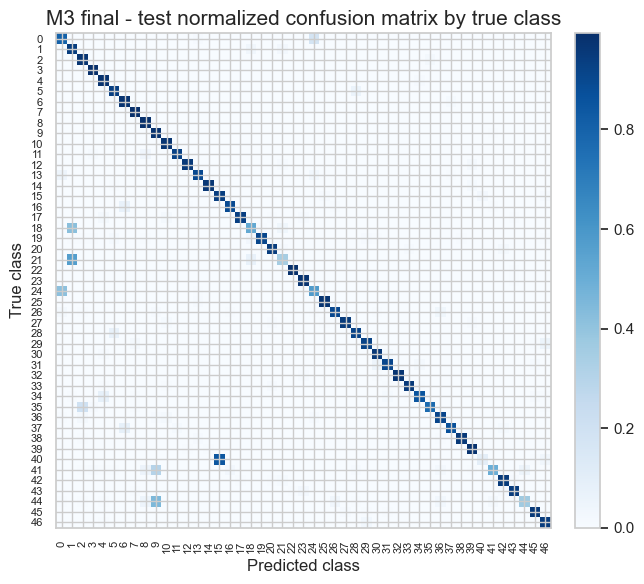

<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 27 - M3 Final: Confusion Diagnostics en Test</h3>

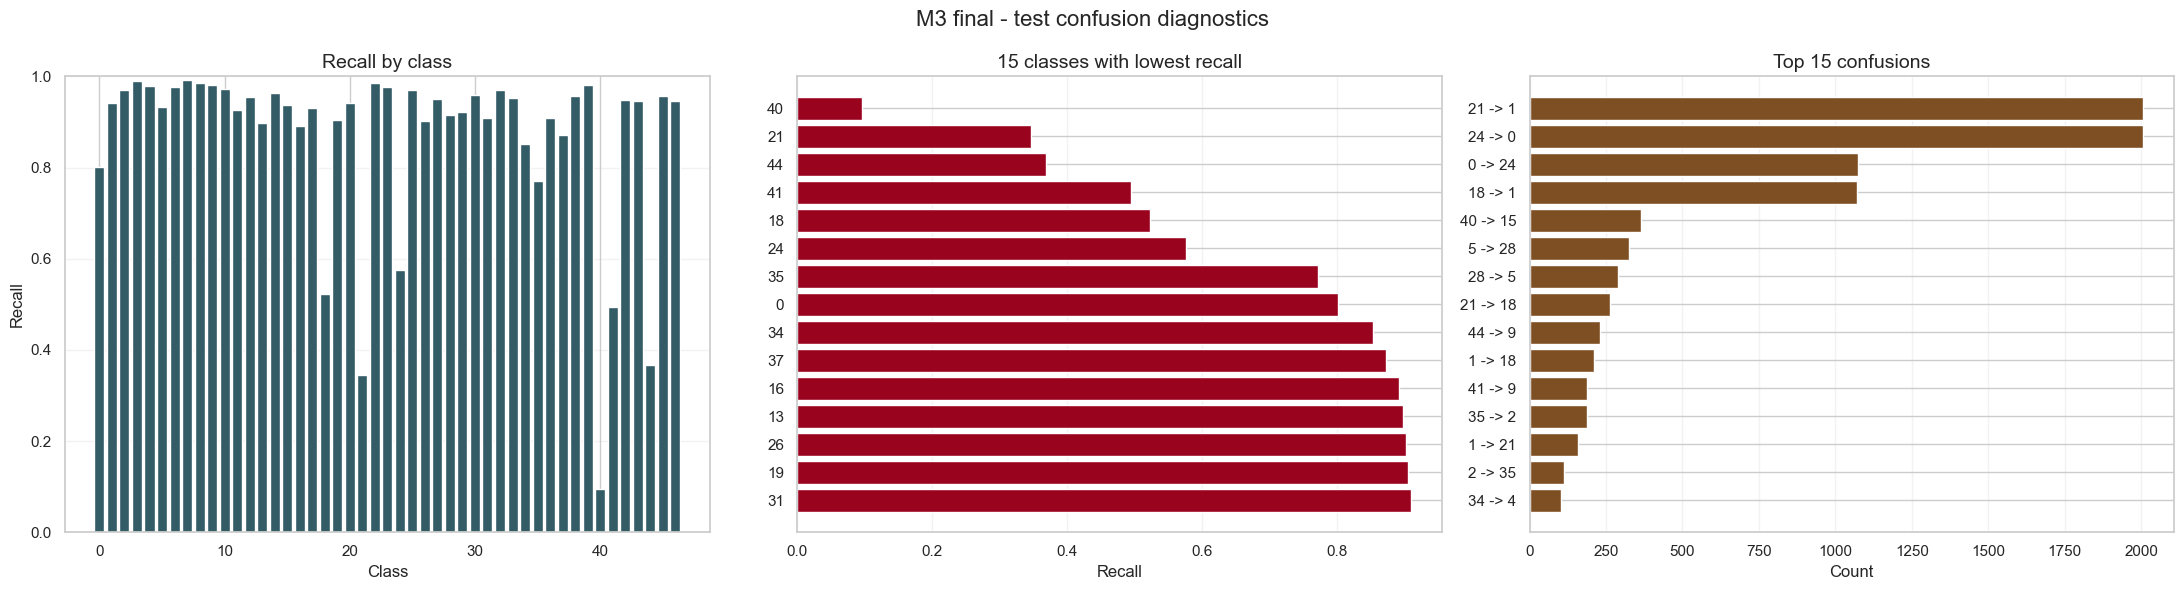

In [41]:
point4_confusions = np.load(DIR_ARTIFACTS / "point4_test_confusion_matrices.npz")
m3_test_confusion = point4_confusions["m3_confusion_matrix"]

mostrar_titulo("Grafico 26", "M3 Final: Normalized Confusion Matrix en Test")
fig, _ = graficar_confusion_matrix(
    m3_test_confusion,
    title="M3 final - test normalized confusion matrix by true class",
    normalizar=True,
    annotate=False,
)
plt.show()

mostrar_titulo("Grafico 27", "M3 Final: Confusion Diagnostics en Test")
fig, axes, m3_per_class, m3_top_confusions = graficar_confusion_diagnostics(
    m3_test_confusion,
    top_n=15,
    title="M3 final - test confusion diagnostics",
)
plt.show()


**Lectura.** En test, la `confusion matrix` de `M3` tiene una diagonal muy marcada, coherente con una `accuracy` cercana a `0.899`. De todos modos, siguen existiendo errores dificiles: aparecen confusiones como `21 -> 1`, `24 -> 0`, `0 -> 24` y `18 -> 1`. Esto sugiere que el problema restante se concentra en pares de caracteres visualmente parecidos, no en una falla general del modelo.


### 4.c - Comparacion final en test: M0, M1, M2 y M3

La comparacion final se hace sobre `test`, que no participo en la seleccion de hiperparametros. Asi separo los roles de cada split:

- `train`: ajustar pesos;
- `validation`: elegir arquitectura e hiperparametros;
- `test`: estimar performance final.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 28 - Comparacion Final en Test</h3>

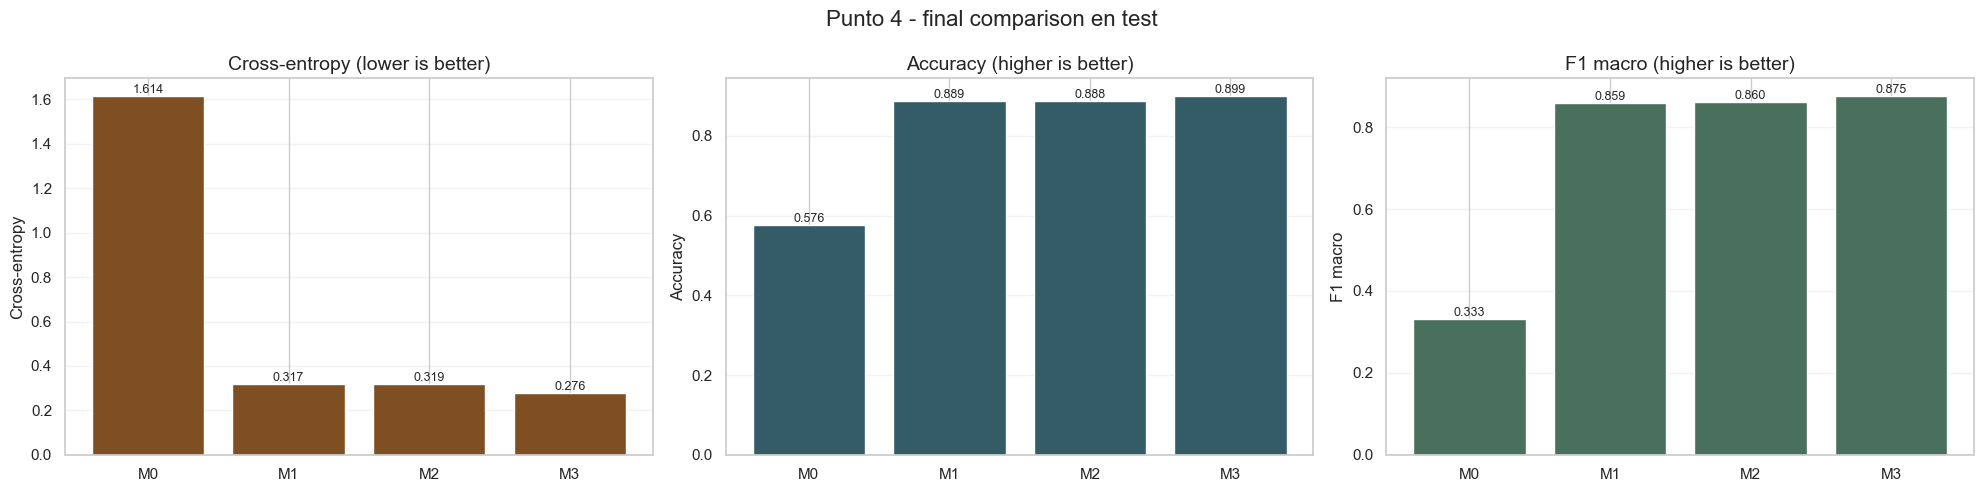

In [42]:
point4_test_summary = pd.read_csv(DIR_ARTIFACTS / "point4_test_summary.csv")

mostrar_titulo("Grafico 28", "Comparacion Final en Test")
fig, _ = graficar_comparacion_modelos_finales(
    point4_test_summary,
    title="Punto 4 - final comparison en test",
)
plt.show()


**Lectura.** En `test`, `M3` queda primero en las tres metricas principales: `cross-entropy=0.2763`, `accuracy=0.8993` y `F1 macro=0.8753`. `M1` y `M2` quedan muy parecidos entre si, lo cual confirma que PyTorch replica bien el modelo NumPy. La mejora real aparece recien con el pool PyTorch y la eleccion de `M3`. `M0` queda lejos, sobre todo en `F1 macro`.


### 4.d - Robustez ante ruido

Para estudiar robustez, perturbo `test` con ruido gaussiano sobre pixels normalizados:

$$\tilde{x} = clip(x + \epsilon, 0, 1), \qquad \epsilon \sim \mathcal{N}(0, \sigma^2)$$

Pruebo distintos valores de `sigma`. Esta prueba no reemplaza al `test` limpio, pero sirve para ver como se degrada cada modelo cuando las imagenes se alejan de la distribucion original.


<h3 style='font-size:23px; margin:18px 0 8px 0;'>Grafico 29 - Robustness ante Noise en Test</h3>

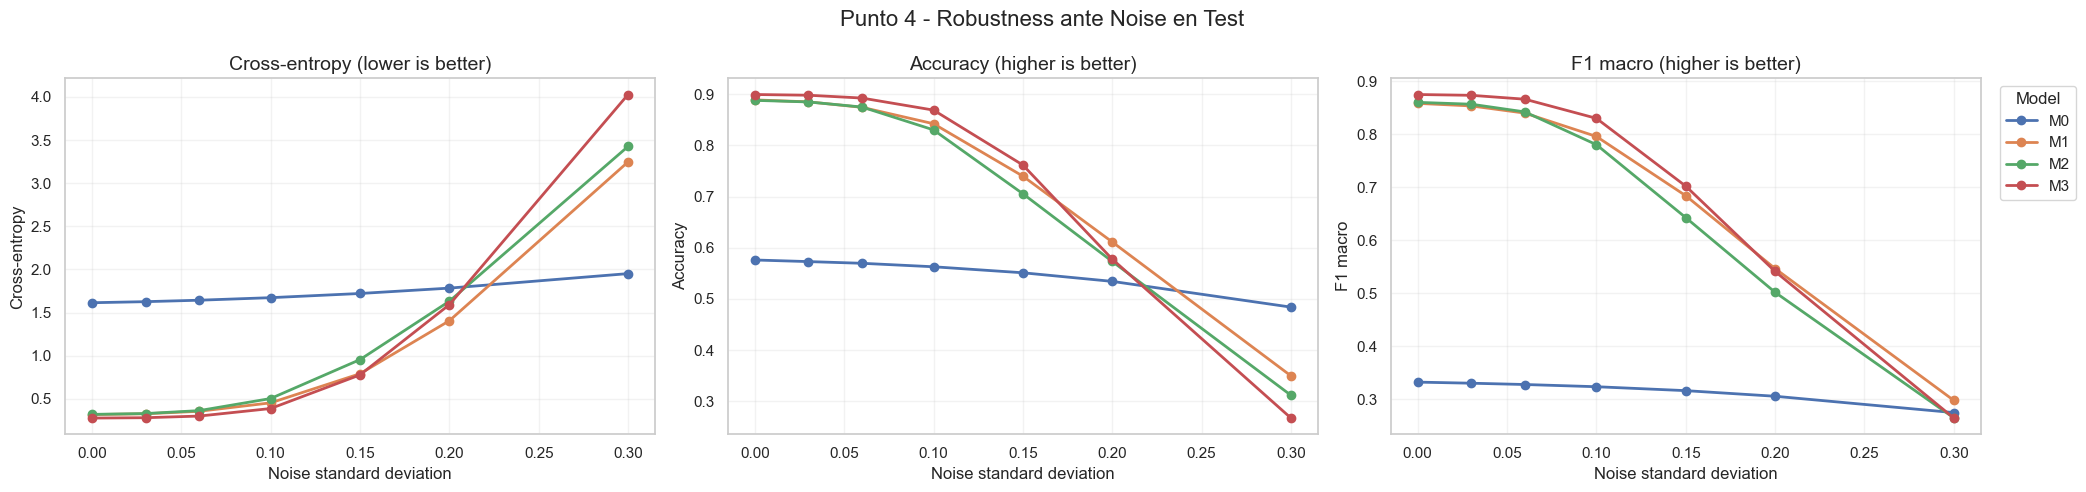

In [43]:
point4_noise = pd.read_csv(DIR_ARTIFACTS / "point4_noise_robustness.csv")

mostrar_titulo("Grafico 29", "Robustness ante Noise en Test")
fig, _ = graficar_robustness_noise(
    point4_noise,
    title="Punto 4 - Robustness ante Noise en Test",
)
plt.show()


**Lectura.** Con imagenes limpias y ruido moderado, `M3` es el modelo mas solido. Para `sigma=0.10` mantiene `accuracy=0.8689` y `F1 macro=0.8303`, por encima de `M1` y `M2`. Para ruido extremo (`sigma=0.20` y `0.30`) todos los modelos se degradan fuerte y el ranking se vuelve menos estable. Esa zona muestra un limite razonable: no cambia la eleccion principal basada en `test` limpio y ruido moderado.


## Conclusion general

El recorrido completo muestra una mejora gradual y justificable:

- `M0` funciona como baseline propio en NumPy, pero queda en underfitting.
- `M1` mejora mucho al combinar `mini-batch training`, `Adam`, mayor capacidad, `L2` y `early stopping`.
- `M2` valida que PyTorch reproduce el comportamiento de `M1` cuando se mantiene la misma familia de modelo.
- `M3` aprovecha el pool PyTorch para sumar `BatchNorm`, `Dropout` y activacion `SiLU`, logrando la mejor performance final.

En `test`, `M3` alcanza la menor `cross-entropy` (`0.2763`), la mayor `accuracy` (`0.8993`) y el mayor `F1 macro` (`0.8753`). Ademas, mantiene la ventaja con ruido bajo y moderado. Por eso lo tomo como el mejor modelo del TP.
